In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
!pip install -q kagglehub

In [57]:
import kagglehub
path = kagglehub.dataset_download("kartik2112/fraud-detection")
print(path)

Using Colab cache for faster access to the 'fraud-detection' dataset.
/kaggle/input/fraud-detection


In [58]:
train = pd.read_csv(f"{path}/fraudTrain.csv", index_col=0)
test = pd.read_csv(f"{path}/fraudTest.csv", index_col=0)
df = pd.concat([train, test], ignore_index=True)
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df = df.sort_values("trans_date_trans_time").reset_index(drop=True)
print(df.shape)
df.head()

(1852394, 22)


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [59]:
print("Taux de fraude :", df["is_fraud"].mean())
print(df.groupby("is_fraud")["amt"].describe())

Taux de fraude : 0.005210014716091717
              count        mean         std   min      25%     50%      75%  \
is_fraud                                                                      
0         1842743.0   67.651278  153.548108  1.00    9.610   47.24   82.560   
1            9651.0  530.661412  391.028873  1.06  240.075  390.00  902.365   

               max  
is_fraud            
0         28948.90  
1          1376.04  


## 1. Chargement et premier aperçu des données

Le jeu de données contient environ **1,85 million de transactions** par carte bancaire, réunies à partir de `fraudTrain.csv` et `fraudTest.csv`, puis triées par date. Le tri chronologique est important, car il nous permettra plus tard de faire une séparation temporelle 60 % / 20 % / 20 % comme en conditions réelles.

### Taux de fraude
Le taux de fraude est d'environ **0,52 %**, soit à peu près une transaction frauduleuse sur 190. Le jeu est donc **extrêmement déséquilibré**. Cela a deux conséquences :
- l'accuracy n'a aucun sens ici, car un modèle qui répond toujours « pas de fraude » aurait 99,5 % de réussite sans rien détecter ;
- nous utiliserons des métriques adaptées aux événements rares (PR-AUC, précision@k, rappel@k) et une stratégie contre le déséquilibre, appliquée uniquement sur l'ensemble d'entraînement.

### Montants selon la classe
Les fraudes ont des montants beaucoup plus élevés que les transactions normales : la moyenne est d'environ **531 $** pour les fraudes contre **68 $** pour les transactions légitimes, et la médiane est d'environ **390 $** contre **47 $**. Le montant (`amt`) sera donc une variable très informative.

Les transactions légitimes ont aussi des valeurs extrêmes jusqu'à environ 28 949 $, alors que les fraudes  ne dépassent pas environ 1 376 $. Cela suggère que les fraudeurs visent des montants élevés mais pas exceptionnels.

### Ce que nous retenons pour la suite
Le déséquilibre nous oblige à choisir les bonnes métriques et à définir un seuil d'alerte selon un coût métier. Le montant sera une variable clé, et les variables comportementales (vélocité, écart au profil de la carte) viendront compléter l'information.

In [60]:
def table_taux(col):
    t = df.groupby(col, observed=True)["is_fraud"].agg(transactions="count", fraudes="sum", taux="mean")
    t["taux_%"] = (t["taux"] * 100).round(3)
    return t.drop(columns="taux")

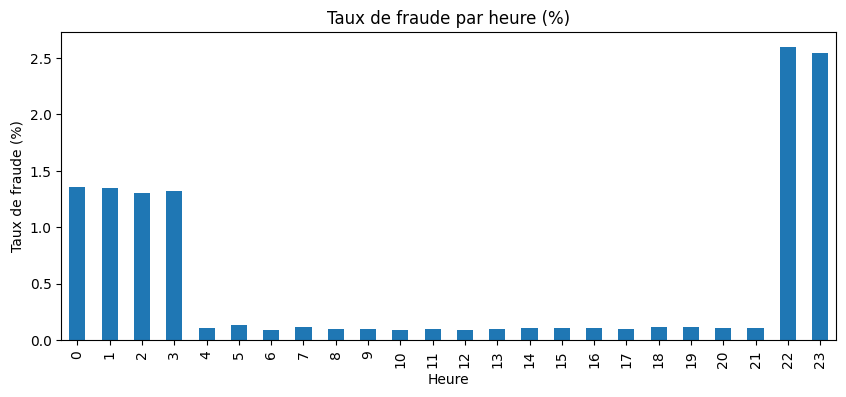

,transactions,fraudes,taux_%
hour,,,
0,60655,823,1.357
1,61330,827,1.348
2,60796,793,1.304
3,60968,803,1.317
4,59938,61,0.102
5,60088,80,0.133
6,60406,54,0.089
7,60301,72,0.119
8,60498,59,0.098


In [61]:
df["hour"] = df["trans_date_trans_time"].dt.hour
rate_hour = df.groupby("hour")["is_fraud"].mean() * 100
rate_hour.plot(kind="bar", figsize=(10, 4), title="Taux de fraude par heure (%)")
plt.xlabel("Heure")
plt.ylabel("Taux de fraude (%)")
plt.show()
display(table_taux("hour"))

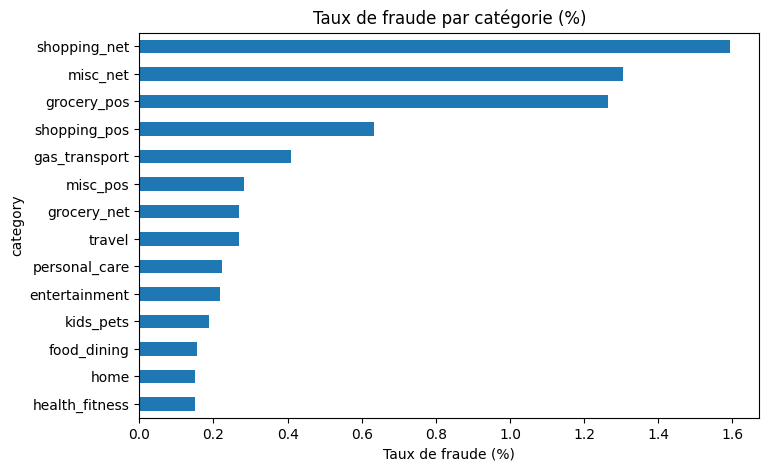

,transactions,fraudes,taux_%
category,,,
shopping_net,139322,2219,1.593
misc_net,90654,1182,1.304
grocery_pos,176191,2228,1.265
shopping_pos,166463,1056,0.634
gas_transport,188029,772,0.411
misc_pos,114229,322,0.282
grocery_net,64878,175,0.270
travel,57956,156,0.269
personal_care,130085,290,0.223


In [62]:
rate_cat = df.groupby("category")["is_fraud"].mean().sort_values() * 100
rate_cat.plot(kind="barh", figsize=(8, 5), title="Taux de fraude par catégorie (%)")
plt.xlabel("Taux de fraude (%)")
plt.show()
display(table_taux("category").sort_values("taux_%", ascending=False))

/tmp/ipykernel_2970/4056814076.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  rate_month = df.set_index("trans_date_trans_time")["is_fraud"].resample("M").mean() * 100


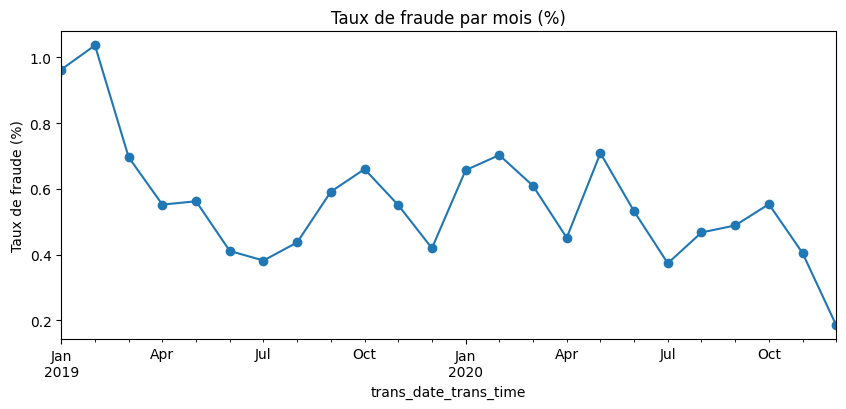

,transactions,fraudes,taux_%
month,,,
2019-01,52525,506,0.963
2019-02,49866,517,1.037
2019-03,70939,494,0.696
2019-04,68078,376,0.552
2019-05,72532,408,0.563
2019-06,86064,354,0.411
2019-07,86596,331,0.382
2019-08,87359,382,0.437
2019-09,70652,418,0.592


In [63]:
rate_month = df.set_index("trans_date_trans_time")["is_fraud"].resample("M").mean() * 100
rate_month.plot(figsize=(10, 4), marker="o", title="Taux de fraude par mois (%)")
plt.ylabel("Taux de fraude (%)")
plt.show()
df["month"] = df["trans_date_trans_time"].dt.to_period("M")
display(table_taux("month"))

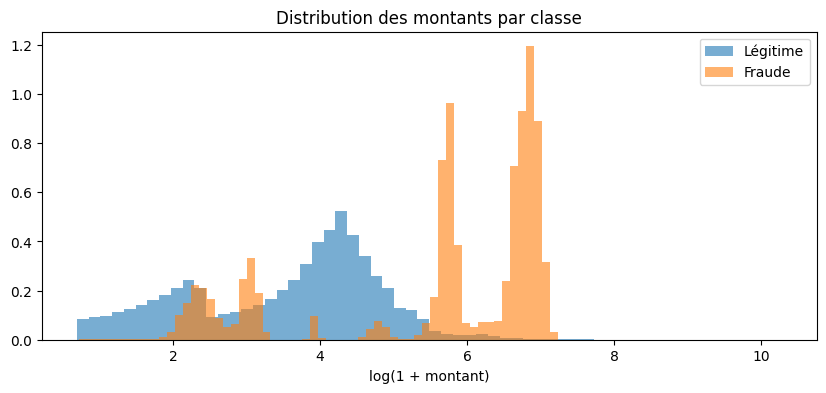

In [64]:
plt.figure(figsize=(10, 4))
plt.hist(np.log1p(df.loc[df["is_fraud"] == 0, "amt"]), bins=60, alpha=0.6, density=True, label="Légitime")
plt.hist(np.log1p(df.loc[df["is_fraud"] == 1, "amt"]), bins=60, alpha=0.6, density=True, label="Fraude")
plt.xlabel("log(1 + montant)")
plt.title("Distribution des montants par classe")
plt.legend()
plt.show()

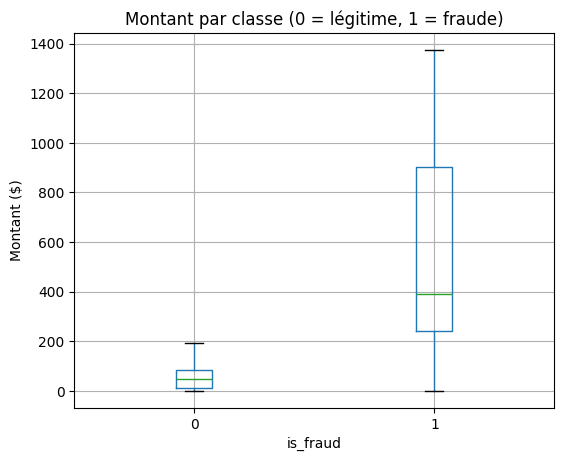

In [65]:
df.boxplot(column="amt", by="is_fraud", figsize=(6, 5), showfliers=False)
plt.title("Montant par classe (0 = légitime, 1 = fraude)")
plt.suptitle("")
plt.ylabel("Montant ($)")
plt.show()

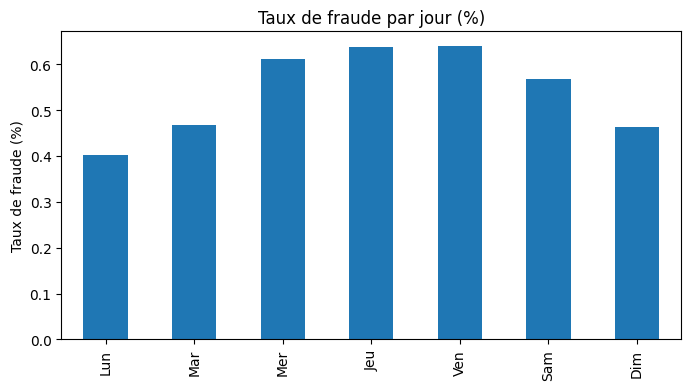

,transactions,fraudes,taux_%
dow,,,
0,369418,1484,0.402
1,270340,1266,0.468
2,183913,1125,0.612
3,206741,1317,0.637
4,215078,1376,0.640
5,263227,1493,0.567
6,343677,1590,0.463


In [66]:
df["dow"] = df["trans_date_trans_time"].dt.dayofweek
rate_dow = df.groupby("dow")["is_fraud"].mean() * 100
rate_dow.index = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
rate_dow.plot(kind="bar", figsize=(8, 4), title="Taux de fraude par jour (%)")
plt.ylabel("Taux de fraude (%)")
plt.show()
display(table_taux("dow"))

In [67]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["lat"], df["long"], df["merch_lat"], df["merch_long"])
df.groupby("is_fraud")["distance_km"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1842743.0,76.110969,29.118287,0.022255,55.318729,78.216697,98.510204,152.117173
1,9651.0,76.256233,28.865545,0.738769,55.573136,78.101922,98.418296,144.522410


### Distance entre le client et le marchand

 l'hypothèse selon laquelle les fraudes auraient lieu plus loin du domicile du client. Les résultats montrent que ce n'est pas le cas : la distance moyenne est d'environ 76 km pour les deux classes, et les médianes (environ 78 km) et les quartiles sont presque identiques.

Cette variable ne permet donc pas de distinguer les fraudes des transactions légitimes. Ce résultat s'explique probablement par **la nature synthétique du jeu de données** : le simulateur génère la position du marchand de la même façon pour toutes les transactions. **Nous ne retiendrons pas cette variable comme variable principale**, mais nous la laissons dans le jeu pour que le modèle puisse confirmer qu'elle n'apporte rien (par exemple avec SHAP).

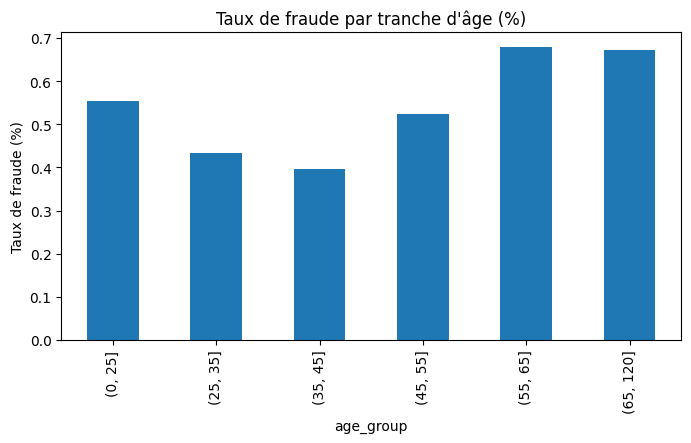

,transactions,fraudes,taux_%
age_group,,,
"(0, 25]",198500,1100,0.554
"(25, 35]",422059,1830,0.434
"(35, 45]",383483,1522,0.397
"(45, 55]",352762,1850,0.524
"(55, 65]",233077,1585,0.680
"(65, 120]",262513,1764,0.672


In [68]:
df["age"] = (df["trans_date_trans_time"] - pd.to_datetime(df["dob"])).dt.days // 365
df["age_group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 120])
rate_age = df.groupby("age_group", observed=True)["is_fraud"].mean() * 100
rate_age.plot(kind="bar", figsize=(8, 4), title="Taux de fraude par tranche d'âge (%)")
plt.ylabel("Taux de fraude (%)")
plt.show()
display(table_taux("age_group"))

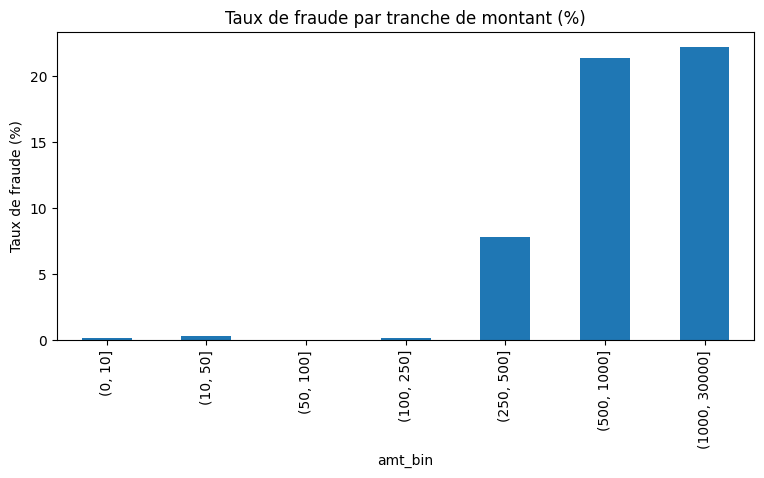

,transactions,fraudes,taux_%
amt_bin,,,
"(0, 10]",480179,675,0.141
"(10, 50]",481050,1394,0.290
"(50, 100]",556287,63,0.011
"(100, 250]",280957,327,0.116
"(250, 500]",32212,2508,7.786
"(500, 1000]",16190,3459,21.365
"(1000, 30000]",5519,1225,22.196


In [69]:
df["amt_bin"] = pd.cut(df["amt"], bins=[0, 10, 50, 100, 250, 500, 1000, 30000])
rate_amt = df.groupby("amt_bin", observed=True)["is_fraud"].mean() * 100
rate_amt.plot(kind="bar", figsize=(9, 4), title="Taux de fraude par tranche de montant (%)")
plt.ylabel("Taux de fraude (%)")
plt.show()
display(table_taux("amt_bin"))

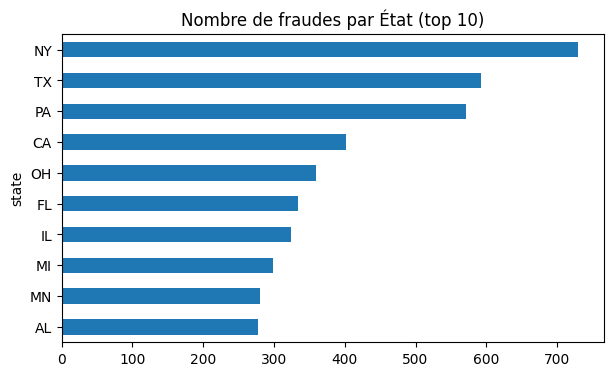

,transactions,fraudes,taux_%
state,,,
NY,119419,730,0.611
TX,135269,592,0.438
PA,114173,572,0.501
CA,80495,402,0.499
OH,66627,360,0.540
FL,60775,334,0.550
IL,62212,324,0.521
MI,65825,299,0.454
MN,45433,280,0.616


In [70]:
df[df["is_fraud"] == 1]["state"].value_counts().head(10).plot(kind="barh", figsize=(7, 4), title="Nombre de fraudes par État (top 10)")
plt.gca().invert_yaxis()
plt.show()
display(table_taux("state").sort_values("fraudes", ascending=False).head(10))

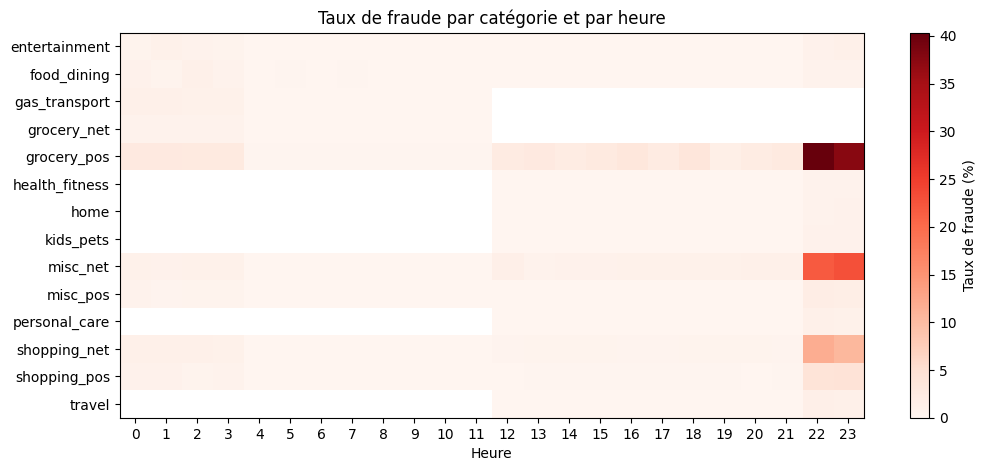

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
category,,,,,,,,,,,,,,,,,,,,,
entertainment,0.51,1.03,0.66,0.58,0.11,0.11,0.05,0.10,0.00,0.05,...,0.05,0.03,0.03,0.03,0.04,0.06,0.06,0.04,0.94,1.12
food_dining,0.80,0.58,1.19,0.68,0.09,0.25,0.09,0.17,0.00,0.08,...,0.00,0.03,0.04,0.04,0.02,0.04,0.03,0.00,0.66,0.69
gas_transport,1.14,1.13,0.99,1.01,0.10,0.11,0.08,0.09,0.06,0.10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grocery_net,0.70,0.64,0.74,0.70,0.04,0.06,0.07,0.04,0.07,0.04,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grocery_pos,2.72,2.69,2.60,2.68,0.22,0.29,0.18,0.24,0.23,0.21,...,2.13,2.66,3.46,2.22,3.57,1.57,2.11,2.61,40.32,37.61
health_fitness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.02,0.08,0.07,0.03,0.05,0.04,0.03,0.03,0.69,0.74
home,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.01,0.03,0.02,0.02,0.02,0.02,0.04,0.04,0.72,0.82
kids_pets,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.05,0.02,0.03,0.04,0.05,0.05,0.03,0.04,0.92,0.93
misc_net,0.95,0.93,1.08,1.08,0.07,0.06,0.05,0.08,0.03,0.10,...,0.81,0.80,1.00,0.97,1.00,1.01,1.16,1.19,21.77,22.90


In [71]:
pivot = df.pivot_table(index="category", columns="hour", values="is_fraud", aggfunc="mean") * 100
plt.figure(figsize=(12, 5))
plt.imshow(pivot, aspect="auto", cmap="Reds")
plt.colorbar(label="Taux de fraude (%)")
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xticks(range(24), range(24))
plt.xlabel("Heure")
plt.title("Taux de fraude par catégorie et par heure")
plt.show()
display(pivot.round(2))

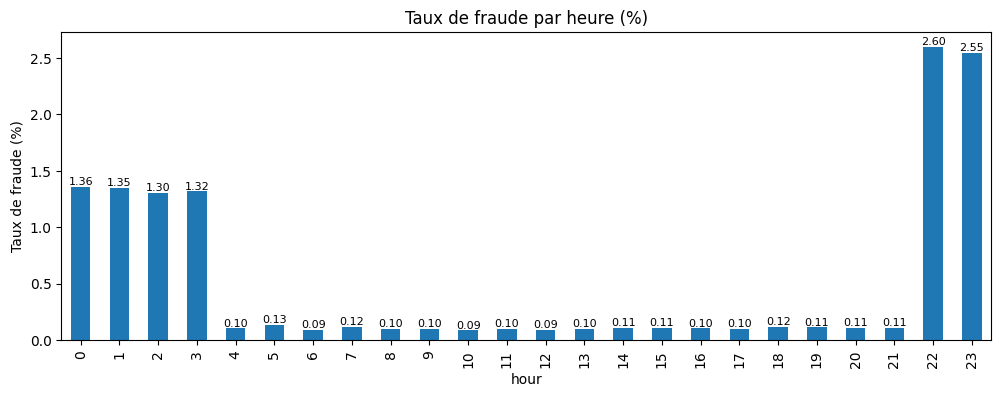

In [72]:
ax = rate_hour.plot(kind="bar", figsize=(12, 4), title="Taux de fraude par heure (%)")
ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=8)
plt.ylabel("Taux de fraude (%)")
plt.show()

## 2. Analyse exploratoire : qui, quand, combien ?

### Quand ? L'heure est un signal très fort
Le taux de fraude est d'environ **0,1 %** pendant la journée (de 4 h à 21 h), alors qu'il monte à **2,6 %** à 22 h et 23 h, puis reste autour de **1,3 %** de minuit à 3 h. Sur ces six heures de nuit (de 22 h à 3 h), on trouve environ **8 169 fraudes sur 9 651, soit 85 % de toutes les fraudes**, alors que le volume de transactions y est plutôt plus faible qu'en journée. Les fraudeurs agissent donc surtout la nuit, quand les titulaires de cartes dorment et surveillent moins leurs comptes.

Cette période traverse minuit (22 h, 23 h, puis 0 h, 1 h...). Si on donnait l'heure au modèle comme un simple nombre de 0 à 23, il croirait que 23 h et 0 h sont très éloignées. C'est pourquoi nous utiliserons un **codage cyclique** (sinus et cosinus) pour l'heure.

### Quand ? Le mois et le jour de la semaine
Le taux de fraude n'est pas stable dans le temps : il est proche de **1 %** début 2019, puis il descend vers 0,4 à 0,7 % et finit à **0,19 %** en décembre 2020. Le nombre de transactions double en décembre (environ 140 000 contre 70 000 les autres mois), ce qui dilue le taux. Cette évolution justifie la **séparation chronologique** : la période de test n'aura pas le même taux de fraude que l'entraînement, comme dans la réalité, et nos métriques devront en tenir compte.

Le jour de la semaine est un signal plus faible : le taux va de 0,40 % (lundi) à 0,64 % (vendredi), mais le nombre de fraudes par jour reste du même ordre. Nous le garderons tout de même comme variable temporelle.

### Combien ? Le montant est le signal le plus fort
Le taux de fraude est inférieur à 0,3 % pour les montants jusqu'à 250 $, mais il saute à **7,8 %** entre 250 et 500 $, puis à **21 à 22 %** au-delà de 500 $. Autrement dit, une transaction de plus de 500 $ sur cinq est frauduleuse. Les transactions de plus de 250 $ ne représentent qu'environ **3 %** du volume, mais elles contiennent environ **75 % des fraudes** (7 192 sur 9 651). Un analyste qui ne regarderait que ces transactions trouverait déjà la majorité des fraudes.

Un détail curieux : la tranche 50 à 100 $ est presque sans fraude (0,011 %). Cela vient probablement du simulateur qui a généré les données, ce qui rappelle que le jeu est synthétique.

### Où ? Les catégories de marchands
Les catégories les plus touchées sont **shopping_net (1,59 %)**, **misc_net (1,30 %)** et **grocery_pos (1,27 %)**, alors que `home`, `health_fitness` et `food_dining` restent autour de 0,15 %. Les achats en ligne (suffixe `_net`) sont plus à risque, ce qui est cohérent avec la réalité, car la carte n'a pas besoin d'être présente.

### Qui ? L'âge et la localisation
L'âge a un effet modéré : les clients de plus de 55 ans sont un peu plus touchés (environ 0,67 %) que ceux de 35 à 45 ans (0,40 %). Pour les États, les taux des dix États les plus touchés restent proches (0,44 à 0,62 %), et le nombre de fraudes suit surtout le volume de transactions, donc l'État n'est pas un bon signal. La distance entre le client et le marchand n'en est pas un non plus (voir plus haut).

### Conclusion : ce que nous retenons pour la modélisation
- Variables fortes : le **montant**, l'**heure** (en codage cyclique) et la **catégorie** du marchand.
- Variables secondaires : le jour de la semaine et l'âge.
- Variables faibles : l'État et la distance, que nous garderons seulement pour vérifier avec SHAP qu'elles n'apportent rien.
- Le fort déséquilibre (0,52 %) et la dérive du taux de fraude dans le temps imposent une séparation chronologique et des métriques adaptées (PR-AUC, précision@k, rappel@k).

In [73]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df[["hour", "hour_sin", "hour_cos", "dow"]].head()

,hour,hour_sin,hour_cos,dow
0,0,0.0,1.0,1
1,0,0.0,1.0,1
2,0,0.0,1.0,1
3,0,0.0,1.0,1
4,0,0.0,1.0,1


In [74]:
df = df.sort_values(["cc_num", "trans_date_trans_time"]).reset_index(drop=True)
ts = df["trans_date_trans_time"].astype("int64").values // 10**9
amt = df["amt"].values
cards = df["cc_num"].values
starts = np.r_[0, np.flatnonzero(cards[1:] != cards[:-1]) + 1, len(df)]
print("Nombre de cartes :", len(starts) - 1)

Nombre de cartes : 999


In [75]:
%%time
n_1h = np.zeros(len(df))
n_24h = np.zeros(len(df))
mean_30d = np.full(len(df), np.nan)
since_prev = np.full(len(df), np.nan)

for a, b in zip(starts[:-1], starts[1:]):
    t = ts[a:b]
    cs = np.r_[0, np.cumsum(amt[a:b])]
    idx = np.arange(b - a)
    lo1 = np.searchsorted(t, t - 3600, side="left")
    lo24 = np.searchsorted(t, t - 86400, side="left")
    lo30 = np.searchsorted(t, t - 30 * 86400, side="left")
    n_1h[a:b] = idx - lo1
    n_24h[a:b] = idx - lo24
    cnt30 = idx - lo30
    sum30 = cs[idx] - cs[lo30]
    mean_30d[a:b] = np.where(cnt30 > 0, sum30 / np.maximum(cnt30, 1), np.nan)
    since_prev[a + 1:b] = np.diff(t)

df["n_1h"] = n_1h
df["n_24h"] = n_24h
df["amt_ratio_30d"] = df["amt"] / mean_30d
df["hours_since_prev"] = since_prev / 3600

CPU times: user 286 ms, sys: 45 µs, total: 286 ms
Wall time: 287 ms


In [76]:
df["amt_ratio_30d"] = df["amt_ratio_30d"].fillna(1.0).clip(upper=50)
df["hours_since_prev"] = df["hours_since_prev"].fillna(720).clip(upper=720)

In [77]:
feats_behav = ["n_1h", "n_24h", "amt_ratio_30d", "hours_since_prev"]
display(df.groupby("is_fraud")[feats_behav].mean().round(3))

,n_1h,n_24h,amt_ratio_30d,hours_since_prev
is_fraud,,,,
0,0.198,4.110,1.017,8.959
1,0.677,4.305,5.556,12.602


In [78]:
df = df.sort_values("trans_date_trans_time").reset_index(drop=True)
n = len(df)
i_train, i_val = int(0.6 * n), int(0.8 * n)
df["split"] = np.where(df.index < i_train, "train", np.where(df.index < i_val, "val", "test"))

resume = df.groupby("split").agg(
    debut=("trans_date_trans_time", "min"),
    fin=("trans_date_trans_time", "max"),
    transactions=("is_fraud", "count"),
    fraudes=("is_fraud", "sum"),
    taux=("is_fraud", "mean"),
)
resume["taux_%"] = (resume["taux"] * 100).round(3)
display(resume.drop(columns="taux").loc[["train", "val", "test"]])

,debut,fin,transactions,fraudes,taux_%
split,,,,,
train,2019-01-01 00:00:18,2020-04-07 07:00:14,1111436,6401,0.576
val,2020-04-07 07:00:36,2020-08-25 01:31:21,370479,1901,0.513
test,2020-08-25 01:31:59,2020-12-31 23:59:34,370479,1349,0.364


In [79]:
num_cols = ["amt", "hour_sin", "hour_cos", "dow", "age", "city_pop", "distance_km",
            "n_1h", "n_24h", "amt_ratio_30d", "hours_since_prev"]
X_all = pd.concat([df[num_cols], pd.get_dummies(df["category"], prefix="cat", dtype=int)], axis=1)
y_all = df["is_fraud"]

X_train, y_train = X_all[df["split"] == "train"], y_all[df["split"] == "train"]
X_val, y_val = X_all[df["split"] == "val"], y_all[df["split"] == "val"]
X_test, y_test = X_all[df["split"] == "test"], y_all[df["split"] == "test"]
print(X_train.shape, X_val.shape, X_test.shape)

(1111436, 25) (370479, 25) (370479, 25)


## 3. Préparation et construction des variables

### Variables temporelles
L'heure est transformée par un **codage cyclique** (`hour_sin`, `hour_cos`) afin que 23 h et 0 h soient proches, ce qui est essentiel puisque la majorité des fraudes ont lieu entre 22 h et 3 h. Le jour de la semaine est conservé tel quel.

### Variables comportementales (sans fuite de données)
Pour chaque carte, nous calculons à partir de **son passé uniquement** (jamais la transaction courante ni le futur) :
- `n_1h` et `n_24h` : nombre de transactions dans la dernière heure et les dernières 24 h ;
- `amt_ratio_30d` : montant rapporté à la moyenne des 30 derniers jours de la carte ;
- `hours_since_prev` : temps écoulé depuis la transaction précédente.

Les fraudes se distinguent nettement par `amt_ratio_30d` (moyenne de 5,6 contre 1,0) et par `n_1h` (0,68 contre 0,20). La variable `n_24h` est peu discriminante (4,31 contre 4,11). La première transaction d'une carte n'a pas d'historique : nous remplaçons les valeurs manquantes par une valeur neutre (ratio de 1, délai plafonné à 30 jours).

### Séparation chronologique 60 % / 20 % / 20 %
| Ensemble | Période | Transactions | Fraudes | Taux |
|---|---|---|---|---|
| Entraînement | janv. 2019 à avr. 2020 | 1 111 436 | 6 401 | 0,576 % |
| Validation | avr. 2020 à août 2020 | 370 479 | 1 901 | 0,513 % |
| Test | août 2020 à déc. 2020 | 370 479 | 1 349 | 0,364 % |

Le taux de fraude diminue au fil du temps : l'ensemble de test est donc plus difficile et plus réaliste qu'une séparation aléatoire. Les identifiants (numéro de carte, nom, numéro de transaction) sont exclus des variables du modèle.

In [80]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

In [81]:
def essayer(X, y, poids=1.0):
    modele = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                           scale_pos_weight=poids, tree_method="hist",
                           n_jobs=-1, random_state=42)
    modele.fit(X, y)
    p = modele.predict_proba(X_val)[:, 1]
    return modele, average_precision_score(y_val, p), roc_auc_score(y_val, p)

In [82]:
%%time
resultats = []

m_base, pr, roc = essayer(X_train, y_train)
resultats.append(["Rien (baseline)", pr, roc])

poids = (y_train == 0).sum() / (y_train == 1).sum()
m_pond, pr, roc = essayer(X_train, y_train, poids)
resultats.append(["Pondération des fraudes", pr, roc])

rng = np.random.RandomState(42)
pos = y_train[y_train == 1].index
neg = y_train[y_train == 0].index
idx = np.r_[pos, rng.choice(neg, size=10 * len(pos), replace=False)]
m_sous, pr, roc = essayer(X_train.loc[idx], y_train.loc[idx])
resultats.append(["Sous-échantillonnage 10:1", pr, roc])

CPU times: user 1min 39s, sys: 184 ms, total: 1min 39s
Wall time: 59.5 s


In [83]:
tab = pd.DataFrame(resultats, columns=["Stratégie", "PR-AUC validation", "ROC-AUC validation"]).round(4)
display(tab)

,Stratégie,PR-AUC validation,ROC-AUC validation
0,Rien (baseline),0.9297,0.9985
1,Pondération des fraudes,0.9251,0.9989
2,Sous-échantillonnage 10:1,0.9304,0.9989


**Stratégie 1 : ne rien faire (baseline)**. J’ai entraîné XGBoost directement sur les 1,1 million de lignes, telles quelles, sans aucune correction. Cette stratégie sert de point de comparaison : si les deux autres ne font pas mieux qu’elle, c’est qu’elles ne servent à rien sur ce jeu. Son score en validation est de 0,9297 en PR-AUC.
**Stratégie 2 : la pondération des fraudes**. Ici, on garde les mêmes 1,1 million de lignes, mais on dit au modèle qu’une erreur sur une fraude coûte beaucoup plus cher qu’une erreur sur une transaction normale. Concrètement, j’ai calculé le rapport entre le nombre de transactions normales et le nombre de fraudes (environ 170) et je l’ai donné au paramètre scale_pos_weight de XGBoost. Pendant l’apprentissage, chaque fraude compte alors comme environ 170 transactions normales. Le modèle est ainsi obligé de s’intéresser aux fraudes, sans qu’on supprime aucune donnée. Son score est de 0,9251, donc un peu en dessous de la baseline.

**Stratégie 3 : le sous-échantillonnage 10:1**. Ici, on change les données elles-mêmes. J’ai gardé les 6 401 fraudes, et je n’ai gardé que 64 010 transactions normales, tirées au hasard parmi les 1,1 million (dix fois le nombre de fraudes). Le jeu d’entraînement passe ainsi de 1,1 million à environ 70 000 lignes, et la proportion de fraudes monte de 0,58 % à environ 9 %. Le modèle voit beaucoup plus de fraudes relativement aux transactions normales, et il s’entraîne bien plus vite. Son score est de 0,9304, le meilleur des trois, mais seulement de très peu.

Le point commun important est que ces trois stratégies **ne touchent que le jeu d’entraînement**. La validation et le test restent tels quels, avec leur vrai taux de fraude, car c’est ce qui se passera en vrai : un analyste recevra des transactions avec 0,5 % de fraudes, pas 9 %.

### Stratégie contre le déséquilibre (appliquée au seul jeu d'entraînement)

Nous avons comparé trois stratégies avec le même modèle XGBoost, évaluées sur l'ensemble de validation :

| Stratégie | PR-AUC validation | ROC-AUC validation |
|---|---|---|
| Rien (baseline) | 0,9297 | 0,9985 |
| Pondération des fraudes | 0,9251 | 0,9989 |
| Sous-échantillonnage 10:1 | 0,9304 | 0,9989 |

Les trois stratégies donnent des performances quasiment identiques : l'écart de PR-AUC (moins de 0,006) est trop faible pour être significatif. XGBoost gère donc bien le déséquilibre de ce jeu même sans correction.

Nous retenons le **sous-échantillonnage 10:1** (conservation de toutes les fraudes et de dix fois plus de transactions légitimes tirées au hasard) car il obtient le meilleur score en validation et réduit fortement le temps d'entraînement (environ 70 000 lignes au lieu de 1,1 million). Il a pour effet de gonfler les probabilités prédites, ce qui n'a pas d'incidence ici puisque le seuil d'alerte est choisi sur la validation. Les ensembles de validation et de test ne sont jamais rééquilibrés.

conclusion de la comparaison est que les trois scores sont presque pareils. Cela veut dire que, pour ce jeu, XGBoost se débrouille déjà bien avec le déséquilibre, parce que les fraudes se distinguent nettement par leurs variables (montant, heure, amt_ratio_30d). On a donc retenu **la stratégie 3**, non pas parce qu’elle est bien meilleure, mais parce qu’elle est au moins aussi bonne et beaucoup plus rapide.

In [84]:
scores = {}
scores["XGBoost (sous-éch. 10:1)"] = {
    "val": m_sous.predict_proba(X_val)[:, 1],
    "test": m_sous.predict_proba(X_test)[:, 1],
}

In [85]:
%%time
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
iso.fit(X_train)
scores["Isolation Forest"] = {
    "val": -iso.score_samples(X_val),
    "test": -iso.score_samples(X_test),
}

CPU times: user 10.8 s, sys: 115 ms, total: 10.9 s
Wall time: 9.78 s


In [86]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [108]:
%%time
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight="balanced", max_iter=1000)

lr.fit(scaler.transform(X_train.loc[idx]), y_train.loc[idx])

scores["Régression logistique pondérée"] = {
    "val": lr.predict_proba(scaler.transform(X_val))[:, 1],
    "test": lr.predict_proba(scaler.transform(X_test))[:, 1],
}

CPU times: user 448 ms, sys: 948 µs, total: 449 ms
Wall time: 471 ms


In [88]:
%%time
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=42)
rf.fit(X_train.loc[idx], y_train.loc[idx])
scores["Random Forest"] = {
    "val": rf.predict_proba(X_val)[:, 1],
    "test": rf.predict_proba(X_test)[:, 1],
}

CPU times: user 1min 6s, sys: 176 ms, total: 1min 6s
Wall time: 39.4 s


In [89]:
%%time
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1)
lgbm.fit(X_train.loc[idx], y_train.loc[idx])
scores["LightGBM"] = {
    "val": lgbm.predict_proba(X_val)[:, 1],
    "test": lgbm.predict_proba(X_test)[:, 1],
}

CPU times: user 19.5 s, sys: 24.7 ms, total: 19.5 s
Wall time: 25.3 s


In [109]:
%%time
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
scaler = StandardScaler().fit(X_train)
ech = X_train.sample(20000, random_state=42)
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof.fit(scaler.transform(ech))
scores["LOF"] = {
    "val": -lof.score_samples(scaler.transform(X_val)),
    "test": -lof.score_samples(scaler.transform(X_test)),
}

CPU times: user 1min 58s, sys: 265 ms, total: 1min 58s
Wall time: 1min 59s


In [110]:
%%time
from sklearn.neural_network import MLPRegressor
normales = X_train[y_train == 0].sample(100000, random_state=42)
Xn = scaler.transform(normales)
ae = MLPRegressor(hidden_layer_sizes=(16, 6, 16), max_iter=40, random_state=42)
ae.fit(Xn, Xn)

def erreur(X):
    Z = scaler.transform(X)
    return ((Z - ae.predict(Z)) ** 2).mean(axis=1)

scores["Autoencodeur"] = {"val": erreur(X_val), "test": erreur(X_test)}

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(


CPU times: user 18 s, sys: 34.7 ms, total: 18 s
Wall time: 18.1 s


## 4. Modélisation : méthodes comparées

### Méthodes supervisées
Ces méthodes apprennent avec les étiquettes (fraude ou non). Elles sont entraînées sur le jeu d'entraînement sous-échantillonné (toutes les fraudes et dix fois plus de transactions légitimes).

- **XGBoost** : un gradient boosting qui construit des arbres de décision les uns après les autres, chaque arbre corrigeant les erreurs des précédents. C'est notre modèle de référence.
- **LightGBM** : un autre gradient boosting, qui suit le même principe mais s'entraîne plus vite grâce à une croissance des arbres feuille par feuille.
- **Random Forest** : un ensemble de 200 arbres indépendants, chacun entraîné sur un échantillon aléatoire, dont on moyenne les votes. Il est robuste et peu sensible au sur-apprentissage.
- **Régression logistique pondérée** : un modèle linéaire simple, où les fraudes ont un poids plus fort (`class_weight="balanced"`). Elle sert de base de comparaison facile à interpréter.

### Méthodes non supervisées
Ces méthodes n'utilisent jamais les étiquettes pour apprendre : elles cherchent les transactions inhabituelles, et un score élevé signifie une transaction plus suspecte.

- **Isolation Forest** : il isole chaque transaction par des coupures aléatoires. Une transaction rare ou atypique est isolée en très peu de coupures, ce qui lui donne un score d'anomalie élevé.
- **LOF (Local Outlier Factor)** : il compare la densité autour d'une transaction à celle de ses 20 voisins les plus proches. Une transaction isolée dans une zone peu dense est jugée anormale. Pour limiter le temps de calcul, il est entraîné sur un échantillon de 20 000 transactions.
- **Autoencodeur** : un petit réseau de neurones (16-6-16) entraîné à reconstruire des transactions légitimes uniquement. Une fraude est mal reconstruite, et l'erreur de reconstruction sert de score d'anomalie.


One-Class SVM et DBSCAN n'ont pas été retenus : le temps de calcul de One-Class SVM augmente très vite avec le nombre de lignes, et DBSCAN ne permet pas de calculer un score d'anomalie pour de nouvelles transactions (validation et test) et demande beaucoup de mémoire. LOF et l'autoencodeur couvrent déjà la catégorie des méthodes basées sur la densité et sur la reconstruction.

In [111]:
lignes = []
for nom, s in scores.items():
    lignes.append([nom,
                   average_precision_score(y_val, s["val"]), roc_auc_score(y_val, s["val"]),
                   average_precision_score(y_test, s["test"]), roc_auc_score(y_test, s["test"])])
comparatif = pd.DataFrame(lignes, columns=["Méthode", "PR-AUC val", "ROC-AUC val", "PR-AUC test", "ROC-AUC test"]).round(4)
display(comparatif.sort_values("PR-AUC val", ascending=False))

,Méthode,PR-AUC val,ROC-AUC val,PR-AUC test,ROC-AUC test
3,LightGBM,0.9371,0.9991,0.9284,0.9988
0,XGBoost (sous-éch. 10:1),0.9304,0.9989,0.9191,0.9985
2,Random Forest,0.8813,0.9963,0.8601,0.9954
4,Régression logistique pondérée,0.2165,0.9518,0.1721,0.9494
1,Isolation Forest,0.0921,0.8532,0.0550,0.8380
5,LOF,0.0322,0.7488,0.0194,0.7164
6,Autoencodeur,0.0260,0.7495,0.0194,0.7146


In [112]:
tab = comparatif.sort_values("PR-AUC val", ascending=False)
print(tab.to_markdown(index=False))

| Méthode                        |   PR-AUC val |   ROC-AUC val |   PR-AUC test |   ROC-AUC test |
|:-------------------------------|-------------:|--------------:|--------------:|---------------:|
| LightGBM                       |       0.9371 |        0.9991 |        0.9284 |         0.9988 |
| XGBoost (sous-éch. 10:1)       |       0.9304 |        0.9989 |        0.9191 |         0.9985 |
| Random Forest                  |       0.8813 |        0.9963 |        0.8601 |         0.9954 |
| Régression logistique pondérée |       0.2165 |        0.9518 |        0.1721 |         0.9494 |
| Isolation Forest               |       0.0921 |        0.8532 |        0.055  |         0.838  |
| LOF                            |       0.0322 |        0.7488 |        0.0194 |         0.7164 |
| Autoencodeur                   |       0.026  |        0.7495 |        0.0194 |         0.7146 |


### Tableau comparatif de toutes les méthodes

| Méthode | Type | PR-AUC val | ROC-AUC val | PR-AUC test | ROC-AUC test |
|:--|:--|--:|--:|--:|--:|
| LightGBM | Supervisé | 0,9371 | 0,9991 | 0,9284 | 0,9988 |
| XGBoost (sous-éch. 10:1) | Supervisé | 0,9304 | 0,9989 | 0,9191 | 0,9985 |
| Random Forest | Supervisé | 0,8813 | 0,9963 | 0,8601 | 0,9954 |
| Régression logistique pondérée | Supervisé | 0,2165 | 0,9518 | 0,1721 | 0,9494 |
| Isolation Forest | Non supervisé | 0,0921 | 0,8532 | 0,0550 | 0,8380 |
| LOF | Non supervisé | 0,0322 | 0,7488 | 0,0194 | 0,7164 |
| Autoencodeur | Non supervisé | 0,0260 | 0,7495 | 0,0194 | 0,7146 |

La PR-AUC est la métrique principale, car elle est adaptée aux événements rares. Un classifieur aléatoire obtiendrait environ 0,005 en validation et 0,004 en test (le taux de fraude).

**Lecture des résultats.**
- **Supervisé contre non supervisé.** Les méthodes supervisées sont très nettement supérieures : les deux gradient boosting dépassent 0,91 de PR-AUC sur le test, contre 0,055 au mieux pour les méthodes non supervisées. Ces dernières font pourtant mieux que le hasard (environ 15 fois pour Isolation Forest, 5 fois pour LOF et l'autoencodeur), mais elles ne connaissent pas la fraude : elles repèrent seulement ce qui est inhabituel.
- **Entre les modèles supervisés.** Les modèles à base d'arbres dominent. LightGBM (0,928 sur le test) devance légèrement XGBoost (0,919), puis la Random Forest (0,860). La régression logistique reste loin derrière en PR-AUC (0,172), alors que sa ROC-AUC est correcte (0,949) : un modèle linéaire sait classer globalement les transactions, mais il ne place pas les vraies fraudes tout en haut de la liste. Cela s'explique par l'effet non linéaire du montant observé dans l'exploration (taux de fraude quasi nul sous 250 $, puis 8 % à 22 % au-delà).
- **Entre les méthodes non supervisées.** Isolation Forest est la meilleure des trois, devant LOF et l'autoencodeur, qui obtiennent des résultats très proches.
- **Stabilité.** Tous les scores baissent un peu entre validation et test, ce qui est cohérent avec le taux de fraude plus faible de la période de test (0,36 %).


**Partie A : précision@k et rappel@k**

In [113]:
amt_val = df.loc[X_val.index, "amt"]
amt_test = df.loc[X_test.index, "amt"]

def precision_rappel_at_k(y, s, k):
    top = np.argsort(-s)[:k]
    tp = y.values[top].sum()
    return tp / k, tp / y.sum()

In [139]:
lignes = []
for nom, s in scores.items():
    for ens, y in [("val", y_val), ("test", y_test)]:
        for part in [0.002, 0.005]:
            k = int(part * len(y))
            p, r = precision_rappel_at_k(y, s[ens], k)
            lignes.append([nom, ens, f"{part*100:.1f} %", k, round(p, 4), round(r, 4)])
tab_k = pd.DataFrame(lignes, columns=["Méthode", "Ensemble", "Budget", "k", "Précision@k", "Rappel@k"])
display(tab_k[tab_k["Ensemble"] == "test"].sort_values(["Budget", "Précision@k"], ascending=[True, False]))

,Méthode,Ensemble,Budget,k,Précision@k,Rappel@k
14,LightGBM,test,0.2 %,740,0.9946,0.5456
2,XGBoost (sous-éch. 10:1),test,0.2 %,740,0.9905,0.5434
10,Random Forest,test,0.2 %,740,0.9568,0.5248
18,Régression logistique pondérée,test,0.2 %,740,0.1757,0.0964
6,Isolation Forest,test,0.2 %,740,0.1095,0.0600
22,LOF,test,0.2 %,740,0.0446,0.0245
26,Autoencodeur,test,0.2 %,740,0.0297,0.0163
15,LightGBM,test,0.5 %,1852,0.6782,0.9311
3,XGBoost (sous-éch. 10:1),test,0.5 %,1852,0.6739,0.9251
11,Random Forest,test,0.5 %,1852,0.6334,0.8695


Le budget d’alertes k représente la capacité de traitement des analystes. Nous évaluons deux budgets, 0,2 % et 0,5 % des transactions, afin de montrer le compromis entre précision et rappel.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


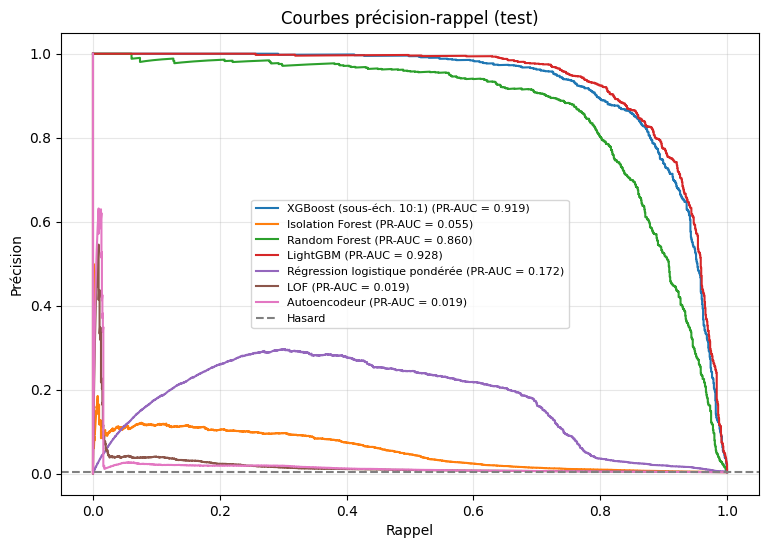

In [115]:
from sklearn.metrics import precision_recall_curve, roc_curve

plt.figure(figsize=(9, 6))
for nom, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s["test"])
    ap = average_precision_score(y_test, s["test"])
    plt.plot(r, p, label=f"{nom} (PR-AUC = {ap:.3f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Hasard")
plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.title("Courbes précision-rappel (test)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

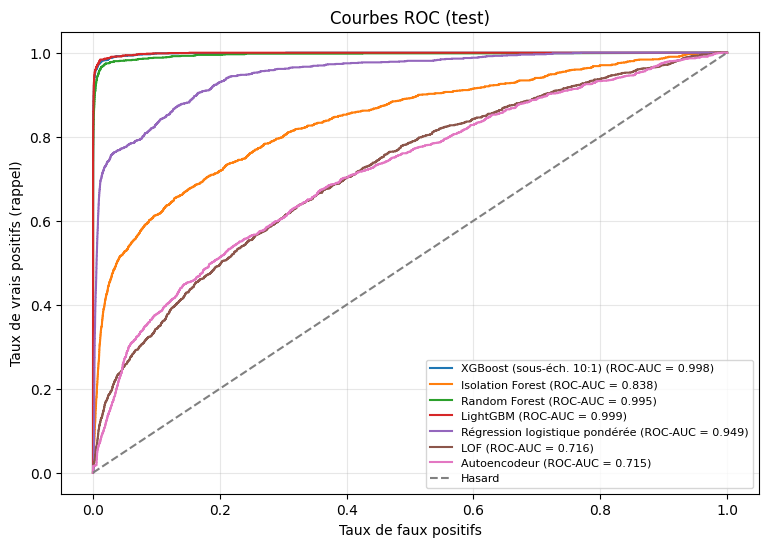

In [116]:
plt.figure(figsize=(9, 6))
for nom, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s["test"])
    auc = roc_auc_score(y_test, s["test"])
    plt.plot(fpr, tpr, label=f"{nom} (ROC-AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.title("Courbes ROC (test)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

In [117]:
from sklearn.metrics import fbeta_score, matthews_corrcoef
cout_alerte = 10

def cout_selon_k(y, s, amt, c):
    ordre = np.argsort(-s)
    m = (amt.values * y.values)[ordre]
    total = m.sum()
    manques = np.r_[total, total - np.cumsum(m)]
    k = np.arange(len(s) + 1)
    return manques + c * k, s[ordre]

def evaluer(y, s, amt, seuil, c):
    alerte = (s >= seuil).astype(int)
    tp = ((alerte == 1) & (y.values == 1)).sum()
    cout = (amt.values * y.values * (1 - alerte)).sum() + c * alerte.sum()
    return {"alertes": int(alerte.sum()),
            "précision": tp / max(alerte.sum(), 1),
            "rappel": tp / y.sum(),
            "F2": fbeta_score(y, alerte, beta=2, zero_division=0),
            "MCC": matthews_corrcoef(y, alerte),
            "coût": cout}

In [118]:
resultats_seuil = []
for nom, s in scores.items():
    cout_v, tries = cout_selon_k(y_val, s["val"], amt_val, cout_alerte)
    k_opt = int(cout_v.argmin())
    seuil = np.inf if k_opt == 0 else tries[k_opt - 1]
    ev = evaluer(y_val, s["val"], amt_val, seuil, cout_alerte)
    et = evaluer(y_test, s["test"], amt_test, seuil, cout_alerte)
    resultats_seuil.append({"Méthode": nom, "Seuil": seuil,
                            "Alertes val": ev["alertes"], "Coût val": ev["coût"],
                            "Alertes test": et["alertes"], "Précision test": et["précision"],
                            "Rappel test": et["rappel"], "F2 test": et["F2"],
                            "MCC test": et["MCC"], "Coût test": et["coût"]})

res = pd.DataFrame(resultats_seuil)
sans_modele_val = (amt_val * y_val).sum()
sans_modele_test = (amt_test * y_test).sum()
res["Économie test (%)"] = (100 * (1 - res["Coût test"] / sans_modele_test)).round(1)
print("Coût sans modèle (aucune alerte) : val =", round(sans_modele_val), "$ | test =", round(sans_modele_test), "$")
display(res.sort_values("Coût test").round(4))

Coût sans modèle (aucune alerte) : val = 989313 $ | test = 733912 $


,Méthode,Seuil,Alertes val,Coût val,Alertes test,Précision test,Rappel test,F2 test,MCC test,Coût test,Économie test (%)
0,XGBoost (sous-éch. 10:1),0.4452,3015,39729.96,2432,0.5271,0.9503,0.8189,0.7065,33479.62,95.4
3,LightGBM,0.5901,2600,38484.61,2059,0.6183,0.9437,0.8538,0.7628,34245.30,95.3
2,Random Forest,0.4693,2877,46045.04,2321,0.5235,0.9007,0.7872,0.6853,36905.18,95.0
4,Régression logistique pondérée,0.8220,5973,115067.21,5967,0.1595,0.7057,0.4189,0.3312,102965.43,86.0
1,Isolation Forest,0.4831,9627,299451.09,12735,0.0512,0.4833,0.1798,0.1490,290320.73,60.4
5,LOF,1.3899,10359,875449.67,15637,0.0204,0.2365,0.0758,0.0584,706647.14,3.7
6,Autoencodeur,0.4409,27241,772588.46,35290,0.0141,0.3692,0.0612,0.0564,733367.74,0.1


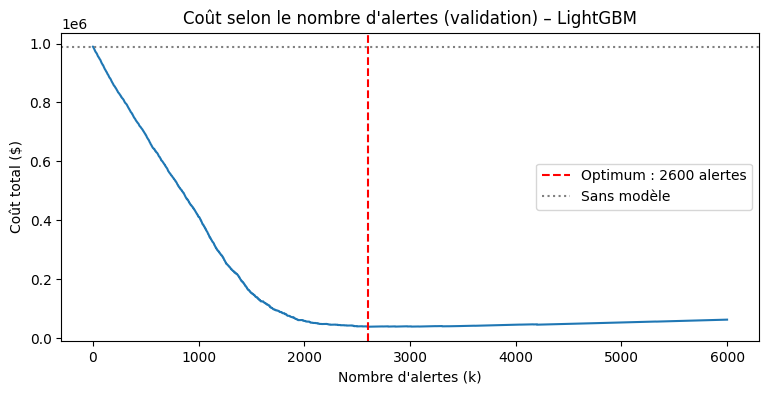

In [119]:
nom_final = "LightGBM"
cout_v, _ = cout_selon_k(y_val, scores[nom_final]["val"], amt_val, cout_alerte)
k_opt = int(cout_v.argmin())
plt.figure(figsize=(9, 4))
plt.plot(cout_v[:6000])
plt.axvline(k_opt, color="red", linestyle="--", label=f"Optimum : {k_opt} alertes")
plt.axhline(sans_modele_val, color="gray", linestyle=":", label="Sans modèle")
plt.xlabel("Nombre d'alertes (k)")
plt.ylabel("Coût total ($)")
plt.title(f"Coût selon le nombre d'alertes (validation) – {nom_final}")
plt.legend()
plt.show()

In [120]:
from sklearn.metrics import confusion_matrix
seuils = res.set_index("Méthode")["Seuil"]

lignes = []
for nom, s in scores.items():
    for ens, y, amt in [("val", y_val, amt_val), ("test", y_test, amt_test)]:
        alerte = (s[ens] >= seuils[nom]).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, alerte, labels=[0, 1]).ravel()
        manques = (amt.values * y.values * (1 - alerte)).sum()
        lignes.append([nom, ens, tn, fp, fn, tp, round(manques), cout_alerte * (fp + tp)])

conf = pd.DataFrame(lignes, columns=["Méthode", "Ensemble", "TN", "FP", "FN", "TP",
                                     "Fraudes manquées ($)", "Coût des alertes ($)"])
conf["Coût total ($)"] = conf["Fraudes manquées ($)"] + conf["Coût des alertes ($)"]
display(conf[conf["Ensemble"] == "test"].sort_values("Coût total ($)"))

,Méthode,Ensemble,TN,FP,FN,TP,Fraudes manquées ($),Coût des alertes ($),Coût total ($)
1,XGBoost (sous-éch. 10:1),test,367980,1150,67,1282,9160,24320,33480
7,LightGBM,test,368344,786,76,1273,13655,20590,34245
5,Random Forest,test,368024,1106,134,1215,13695,23210,36905
9,Régression logistique pondérée,test,364115,5015,397,952,43295,59670,102965
3,Isolation Forest,test,357047,12083,697,652,162971,127350,290321
11,LOF,test,353812,15318,1030,319,550277,156370,706647
13,Autoencodeur,test,334338,34792,851,498,380468,352900,733368


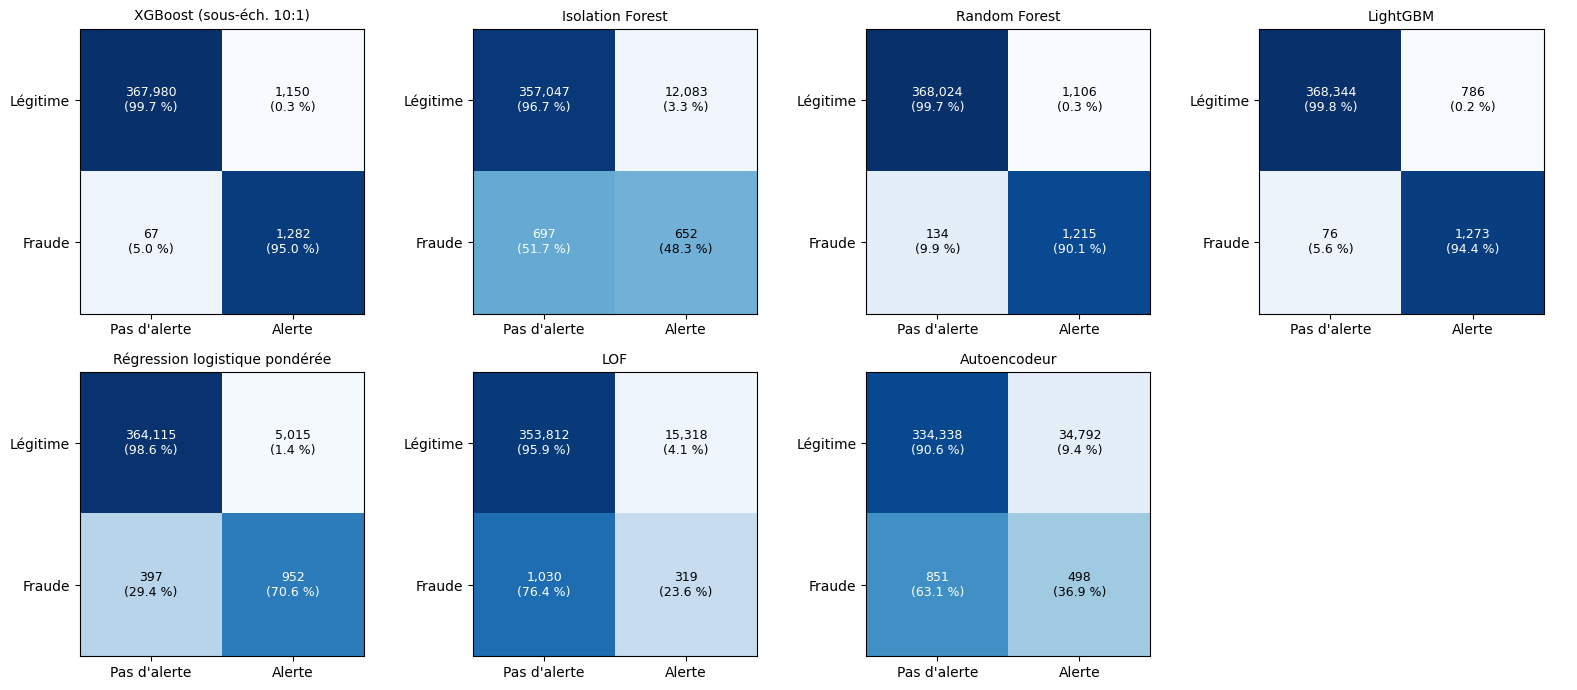

In [121]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
for ax, (nom, s) in zip(axes, scores.items()):
    alerte = (s["test"] >= seuils[nom]).astype(int)
    cm = confusion_matrix(y_test, alerte, labels=[0, 1])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j]):,}\n({cm_norm[i, j] * 100:.1f} %)",
                    ha="center", va="center", fontsize=9,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pas d'alerte", "Alerte"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Légitime", "Fraude"])
    ax.set_title(nom, fontsize=10)
for ax in axes[len(scores):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

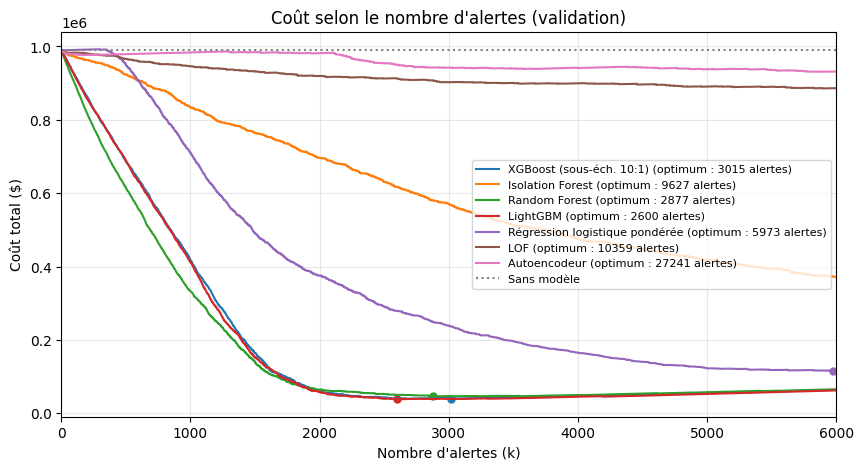

In [122]:
plt.figure(figsize=(10, 5))
for nom, s in scores.items():
    c, _ = cout_selon_k(y_val, s["val"], amt_val, cout_alerte)
    k_opt = int(c.argmin())
    plt.plot(c[:6000], label=f"{nom} (optimum : {k_opt} alertes)")
    plt.scatter(k_opt, c[k_opt], s=25)
plt.axhline(sans_modele_val, color="gray", linestyle=":", label="Sans modèle")
plt.xlim(0, 6000)
plt.xlabel("Nombre d'alertes (k)")
plt.ylabel("Coût total ($)")
plt.title("Coût selon le nombre d'alertes (validation)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

In [123]:
lignes = []
for nom, s in scores.items():
    c_t, _ = cout_selon_k(y_test, s["test"], amt_test, cout_alerte)
    for k in [250, 500, 1000, 2000]:
        p, r = precision_rappel_at_k(y_test, s["test"], k)
        lignes.append([nom, k, round(p, 3), round(r, 3), round(c_t[k])])
balayage = pd.DataFrame(lignes, columns=["Méthode", "k (alertes)", "Précision", "Rappel", "Coût ($)"])
display(balayage.sort_values(["k (alertes)", "Coût ($)"]))

,Méthode,k (alertes),Précision,Rappel,Coût ($)
8,Random Forest,250,0.984,0.182,545658
12,LightGBM,250,1.000,0.185,568984
0,XGBoost (sous-éch. 10:1),250,1.000,0.185,572703
4,Isolation Forest,250,0.104,0.019,713003
24,Autoencodeur,250,0.088,0.016,725112
20,LOF,250,0.088,0.016,726800
16,Régression logistique pondérée,250,0.004,0.001,735228
9,Random Forest,500,0.976,0.362,387376
13,LightGBM,500,0.996,0.369,427534
1,XGBoost (sous-éch. 10:1),500,0.998,0.370,428517


In [135]:
c_fp, c_tp = 10, 10
mode_fn, facteur, c_fn_fixe = "montant", 1.0, 500

def cout_complet(y, s, amt, c_fp, c_tp, mode_fn="montant", facteur=1.0, c_fn_fixe=0.0):
    ordre = np.argsort(-s)
    yy = y.values[ordre]
    aa = amt.values[ordre]
    k = np.arange(len(s) + 1)
    tp = np.r_[0, np.cumsum(yy)]
    fp = k - tp
    perte = facteur * aa * yy if mode_fn == "montant" else c_fn_fixe * yy
    fn_cout = perte.sum() - np.r_[0, np.cumsum(perte)]
    return fn_cout + c_fp * fp + c_tp * tp, s[ordre]

def sans_modele(y, amt):
    return facteur * (amt * y).sum() if mode_fn == "montant" else c_fn_fixe * y.sum()

In [128]:
def cout_au_seuil(y, s, amt, seuil, c_fp, c_tp, mode_fn="montant", facteur=1.0, c_fn_fixe=0.0):
    alerte = s >= seuil
    fraude = y.values == 1
    fp = (alerte & ~fraude).sum()
    tp = (alerte & fraude).sum()
    manques = fraude & ~alerte
    cout_fn = (facteur * amt.values[manques]).sum() if mode_fn == "montant" else c_fn_fixe * manques.sum()
    return cout_fn + c_fp * fp + c_tp * tp

In [136]:
from sklearn.metrics import fbeta_score, matthews_corrcoef

lignes = []
for nom, s in scores.items():
    c_val, tries = cout_complet(y_val, s["val"], amt_val, c_fp, c_tp, mode_fn, facteur, c_fn_fixe)
    k_opt = int(c_val.argmin())
    seuil = np.inf if k_opt == 0 else tries[k_opt - 1]

    a = (s["test"] >= seuil).astype(int)
    fraude = y_test.values == 1
    tp = ((a == 1) & fraude).sum()
    fp = ((a == 1) & ~fraude).sum()
    fn_mask = (a == 0) & fraude
    perte = (facteur * amt_test.values[fn_mask]).sum() if mode_fn == "montant" else c_fn_fixe * fn_mask.sum()
    c_test = perte + c_fp * fp + c_tp * tp

    lignes.append({"Méthode": nom, "Seuil": seuil, "Alertes val": k_opt,
                   "Coût val ($)": round(c_val.min()),
                   "Alertes test": int(a.sum()),
                   "Précision test": tp / max(a.sum(), 1), "Rappel test": tp / fraude.sum(),
                   "F2 test": fbeta_score(y_test, a, beta=2, zero_division=0),
                   "MCC test": matthews_corrcoef(y_test, a),
                   "Coût test ($)": round(c_test),
                   "Économie test (%)": round(100 * (1 - c_test / sans_modele(y_test, amt_test)), 1)})

res = pd.DataFrame(lignes)
seuils = res.set_index("Méthode")["Seuil"]
print("Coût sans modèle : val =", round(sans_modele(y_val, amt_val)), "$ | test =", round(sans_modele(y_test, amt_test)), "$")
display(res.sort_values("Coût test ($)").round(4))

Coût sans modèle : val = 989313 $ | test = 733912 $


,Méthode,Seuil,Alertes val,Coût val ($),Alertes test,Précision test,Rappel test,F2 test,MCC test,Coût test ($),Économie test (%)
0,XGBoost (sous-éch. 10:1),0.4452,3015,39730,2432,0.5271,0.9503,0.8189,0.7065,33480,95.4
3,LightGBM,0.5901,2600,38485,2059,0.6183,0.9437,0.8538,0.7628,34245,95.3
2,Random Forest,0.4693,2877,46045,2321,0.5235,0.9007,0.7872,0.6853,36905,95.0
4,Régression logistique pondérée,0.8220,5973,115067,5967,0.1595,0.7057,0.4189,0.3312,102965,86.0
1,Isolation Forest,0.4831,9627,299451,12735,0.0512,0.4833,0.1798,0.1490,290321,60.4
5,LOF,1.3899,10359,875450,15637,0.0204,0.2365,0.0758,0.0584,706647,3.7
6,Autoencodeur,0.4409,27241,772588,35290,0.0141,0.3692,0.0612,0.0564,733368,0.1


In [131]:
c_fp, c_tp = 10, 10
mode_fn, facteur = "montant", 1.5

lignes = []
for nom, s in scores.items():
    c_val, tries = cout_complet(y_val, s["val"], amt_val, c_fp, c_tp, mode_fn, facteur)
    k_opt = int(c_val.argmin())
    seuil = np.inf if k_opt == 0 else tries[k_opt - 1]
    c_test = cout_au_seuil(y_test, s["test"], amt_test, seuil, c_fp, c_tp, mode_fn, facteur)
    sans_modele = facteur * (amt_test * y_test).sum()
    lignes.append([nom, k_opt, round(c_val.min()), round(c_test), round(100 * (1 - c_test / sans_modele), 1)])

display(pd.DataFrame(lignes, columns=["Méthode", "Alertes optimales (val)", "Coût val ($)",
                                      "Coût test ($)", "Économie test (%)"]).sort_values("Coût test ($)"))

,Méthode,Alertes optimales (val),Coût val ($),Coût test ($),Économie test (%)
3,LightGBM,3337,43091,35519,96.8
0,XGBoost (sous-éch. 10:1),3015,44520,38059,96.5
2,Random Forest,3545,52122,43002,96.1
4,Régression logistique pondérée,6100,142179,125184,88.6
1,Isolation Forest,13791,392940,379147,65.6
6,Autoencodeur,31239,1013837,949200,13.8
5,LOF,20684,1245216,1041083,5.4


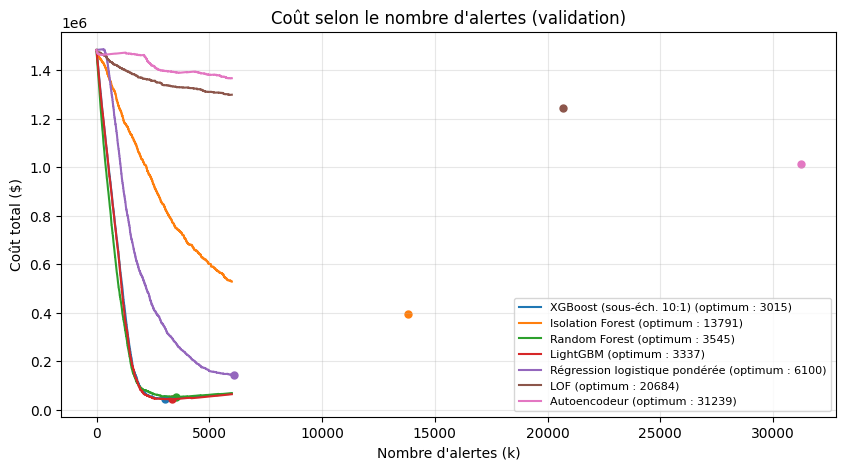

In [134]:
plt.figure(figsize=(10, 5))
for nom, s in scores.items():
    c_val, _ = cout_complet(y_val, s["val"], amt_val, c_fp, c_tp, mode_fn, facteur)
    k_opt = int(c_val.argmin())
    plt.plot(c_val[:6000], label=f"{nom} (optimum : {k_opt})")
    plt.scatter(k_opt, c_val[k_opt], s=25)
plt.xlabel("Nombre d'alertes (k)")
plt.ylabel("Coût total ($)")
plt.title("Coût selon le nombre d'alertes (validation)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

In [140]:
!pip install -q shap

In [141]:
import shap

In [142]:
cols = list(X_train.columns)
rng = np.random.RandomState(42)
idx_fr = rng.choice(np.where(y_test.values == 1)[0], 150, replace=False)
idx_no = rng.choice(np.where(y_test.values == 0)[0], 350, replace=False)
X_ech = X_test.iloc[np.r_[idx_fr, idx_no]]
y_ech = y_test.iloc[np.r_[idx_fr, idx_no]]
bg = X_train.sample(100, random_state=42)
expls = {}

def classe1(sv):
    if isinstance(sv, list):
        return sv[1]
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

def faire_expl(valeurs, base):
    return shap.Explanation(values=valeurs, base_values=np.full(len(valeurs), base),
                            data=X_ech.values, feature_names=cols)

In [143]:
%%time
for nom, m in [("LightGBM", lgbm), ("XGBoost (sous-éch. 10:1)", m_sous), ("Random Forest", rf)]:
    ex = shap.TreeExplainer(m)
    sv = classe1(ex.shap_values(X_ech, check_additivity=False))
    expls[nom] = faire_expl(sv, float(np.ravel(ex.expected_value)[-1]))
print(list(expls))

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


['LightGBM', 'XGBoost (sous-éch. 10:1)', 'Random Forest']
CPU times: user 1min 28s, sys: 208 ms, total: 1min 28s
Wall time: 1min 35s


In [144]:
ex = shap.LinearExplainer(lr, scaler.transform(bg))
sv = ex.shap_values(scaler.transform(X_ech))
expls["Régression logistique pondérée"] = faire_expl(sv, float(np.ravel(ex.expected_value)[-1]))

In [145]:
%%time
def f_iso(A):
    return -iso.score_samples(pd.DataFrame(A, columns=cols))

def f_lof(A):
    return -lof.score_samples(scaler.transform(pd.DataFrame(A, columns=cols)))

def f_ae(A):
    return erreur(pd.DataFrame(A, columns=cols))

for nom, f in [("Isolation Forest", f_iso), ("LOF", f_lof), ("Autoencodeur", f_ae)]:
    e = shap.PermutationExplainer(f, bg.values)(X_ech.values, max_evals=60)
    expls[nom] = shap.Explanation(values=e.values, base_values=e.base_values,
                                  data=X_ech.values, feature_names=cols)
print(list(expls))

PermutationExplainer explainer: 501it [00:57,  7.05it/s]
PermutationExplainer explainer: 501it [05:49,  1.39it/s]


['LightGBM', 'XGBoost (sous-éch. 10:1)', 'Random Forest', 'Régression logistique pondérée', 'Isolation Forest', 'LOF', 'Autoencodeur']
CPU times: user 6min 36s, sys: 696 ms, total: 6min 37s
Wall time: 6min 50s


In [146]:
imp_tab = pd.DataFrame({nom: 100 * np.abs(e.values).mean(0) / np.abs(e.values).mean(0).sum()
                        for nom, e in expls.items()}, index=cols)
top = imp_tab.mean(axis=1).sort_values(ascending=False).head(12).index
display(imp_tab.loc[top].round(1))
imp_tab.to_csv("importance_variables.csv")

,LightGBM,XGBoost (sous-éch. 10:1),Random Forest,Régression logistique pondérée,Isolation Forest,LOF,Autoencodeur
amt,41.7,42.0,42.2,33.7,7.4,9.0,2.3
hour_cos,8.7,10.7,14.5,17.0,1.5,1.6,0.8
amt_ratio_30d,5.7,8.1,11.7,3.7,5.4,6.6,4.2
cat_gas_transport,3.1,2.7,4.6,5.6,5.7,6.2,10.1
cat_shopping_pos,4.1,2.2,0.7,6.3,4.3,4.0,9.3
cat_grocery_pos,3.5,3.3,5.1,2.7,5.7,4.6,5.2
cat_shopping_net,4.0,2.4,1.1,6.2,4.6,5.2,3.6
n_1h,1.3,1.2,2.4,5.6,4.7,8.5,2.6
hours_since_prev,3.8,4.9,4.4,0.6,2.9,2.7,5.6
cat_home,2.0,1.1,0.4,0.9,4.9,4.4,10.9


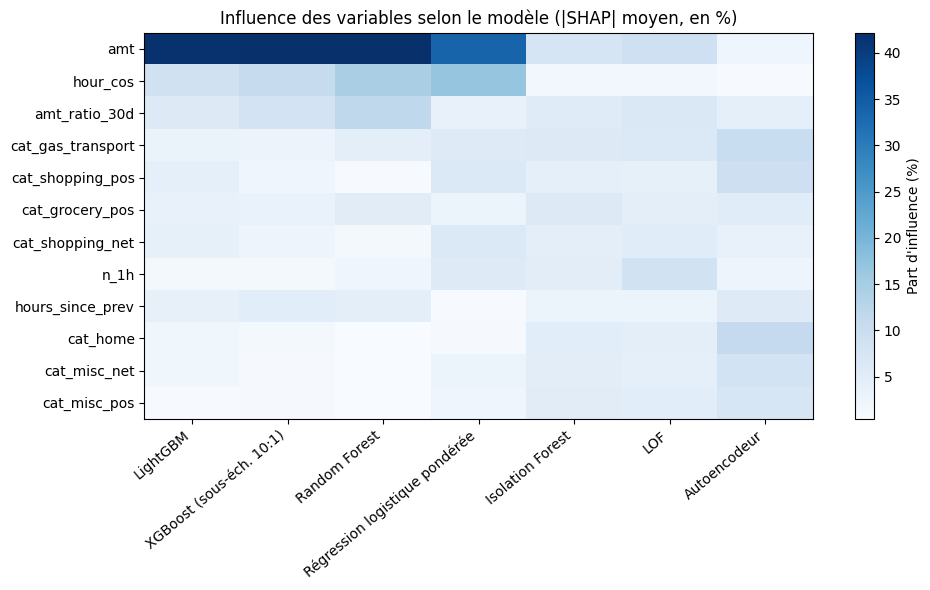

In [147]:
plt.figure(figsize=(10, 6))
plt.imshow(imp_tab.loc[top], aspect="auto", cmap="Blues")
plt.colorbar(label="Part d'influence (%)")
plt.xticks(range(len(imp_tab.columns)), imp_tab.columns, rotation=40, ha="right")
plt.yticks(range(len(top)), top)
plt.title("Influence des variables selon le modèle (|SHAP| moyen, en %)")
plt.tight_layout()
plt.show()

===== LightGBM


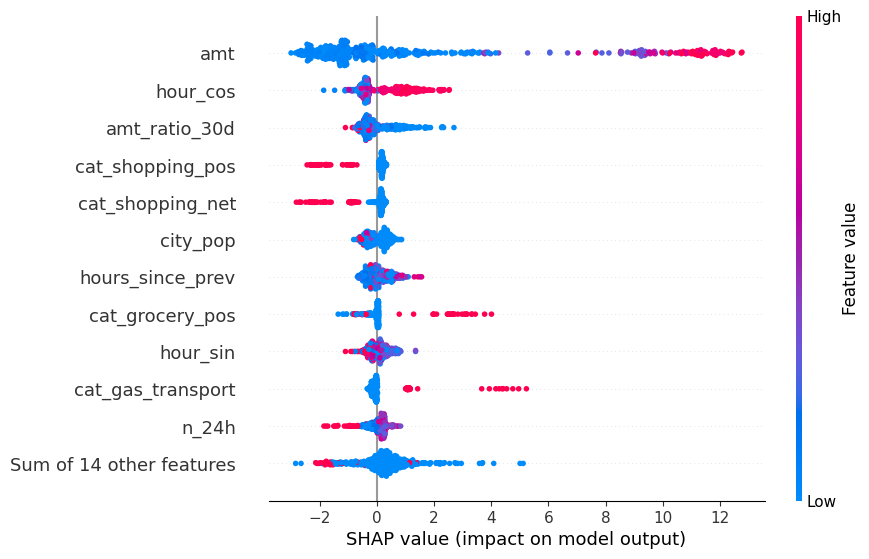

===== XGBoost (sous-éch. 10:1)


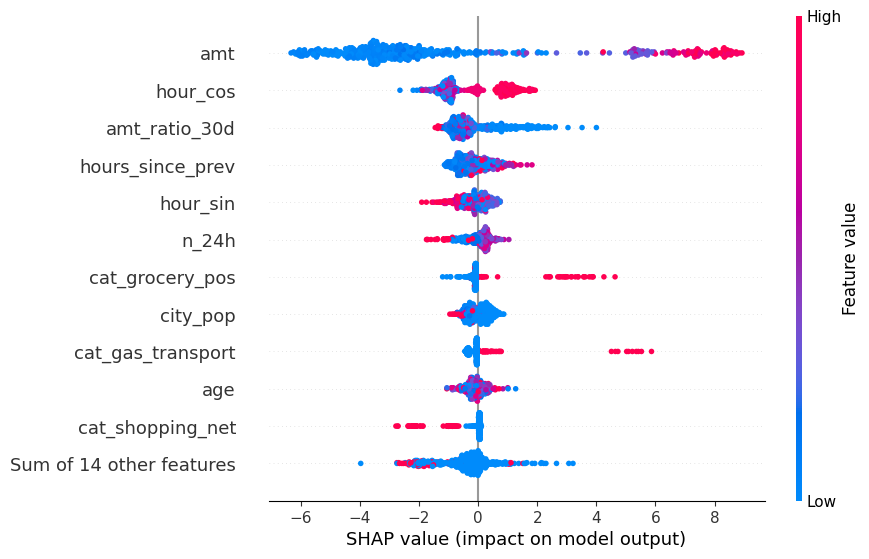

===== Random Forest


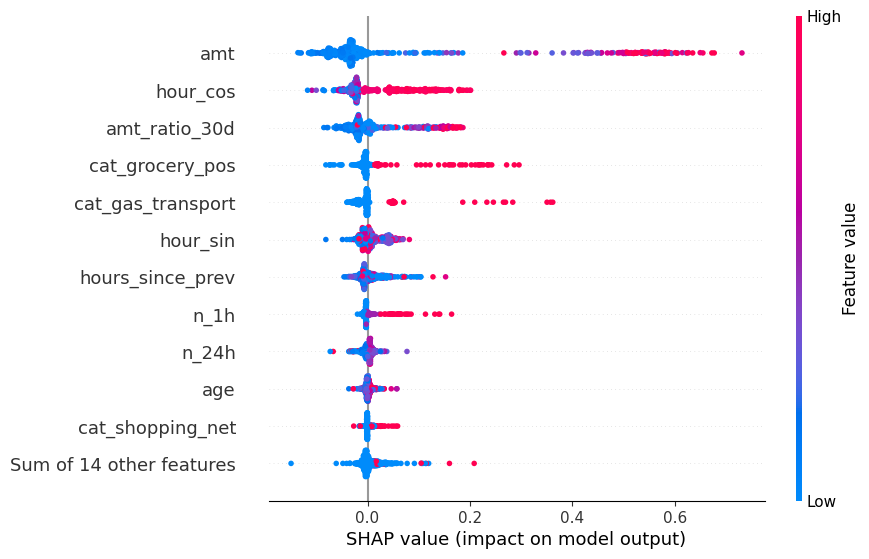

===== Régression logistique pondérée


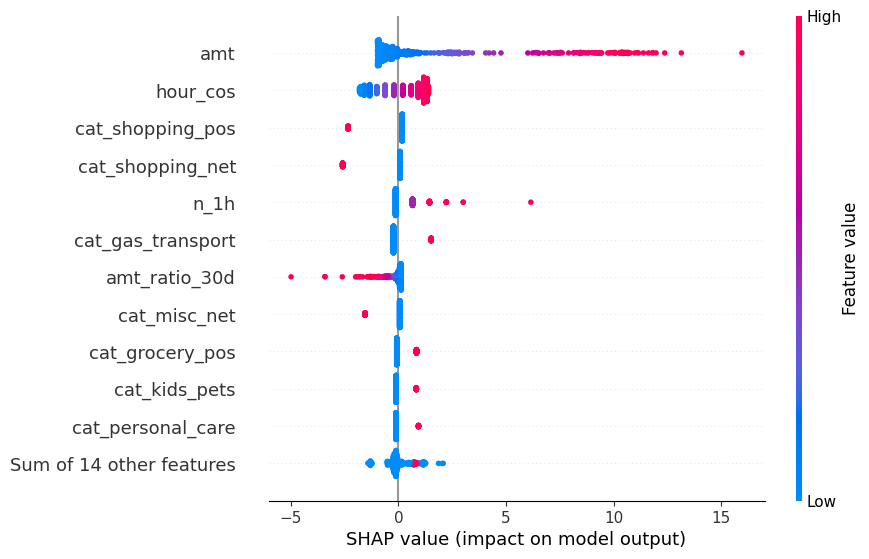

===== Isolation Forest


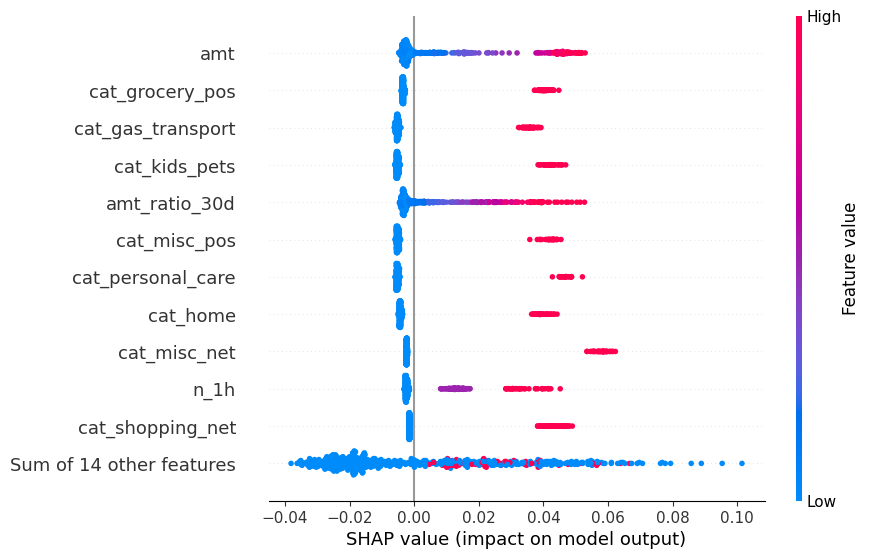

===== LOF


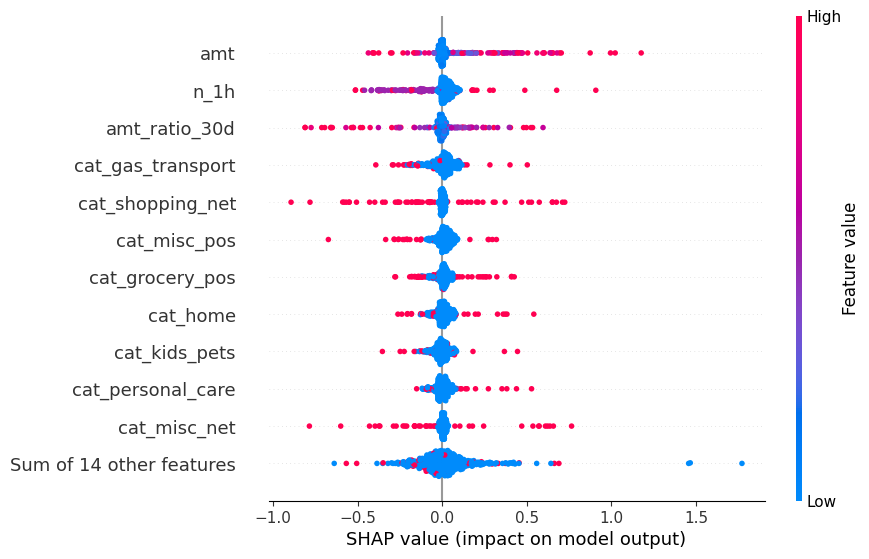

===== Autoencodeur


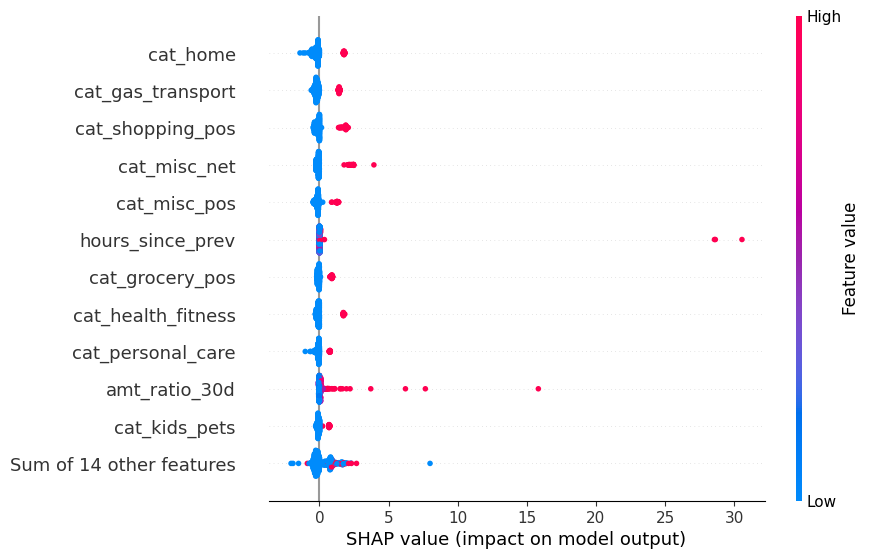

In [148]:
for nom, e in expls.items():
    print("=====", nom)
    shap.plots.beeswarm(e, max_display=12)

In [149]:
fr_pos = np.where(y_ech.values == 1)[0]
p_fr = lgbm.predict_proba(X_ech.iloc[fr_pos])[:, 1]
i_alerte = fr_pos[np.argsort(p_fr)[len(p_fr) // 2]]
print("Montant :", round(float(df.loc[X_ech.index[i_alerte], "amt"]), 2), "$")
display(X_ech.iloc[[i_alerte]].T.loc[num_cols])

Montant : 1148.36 $


,1575588
amt,1148.360000
hour_sin,-0.707107
hour_cos,-0.707107
dow,5.000000
age,56.000000
city_pop,192.000000
distance_km,50.717029
n_1h,0.000000
n_24h,5.000000
amt_ratio_30d,13.736802


===== LightGBM


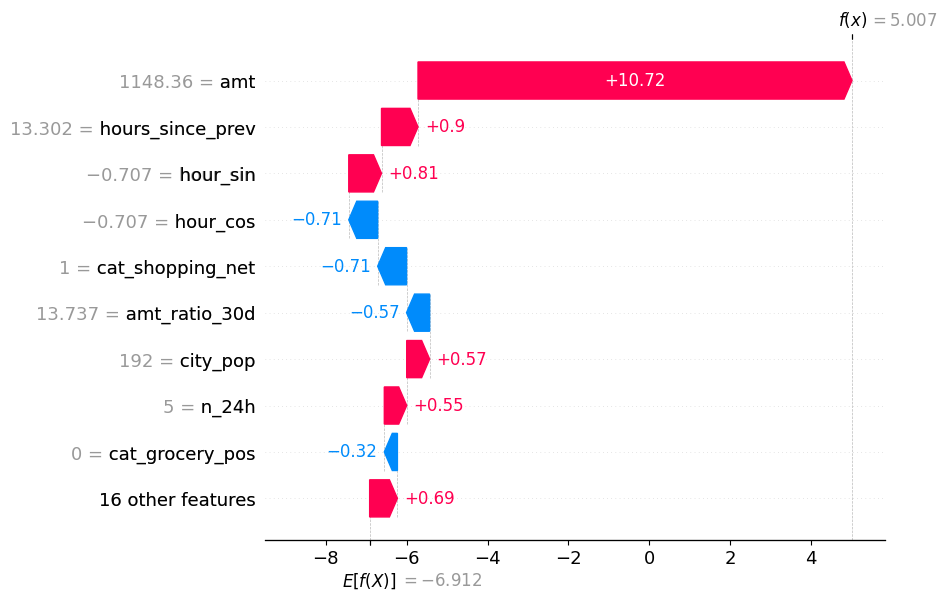

===== XGBoost (sous-éch. 10:1)


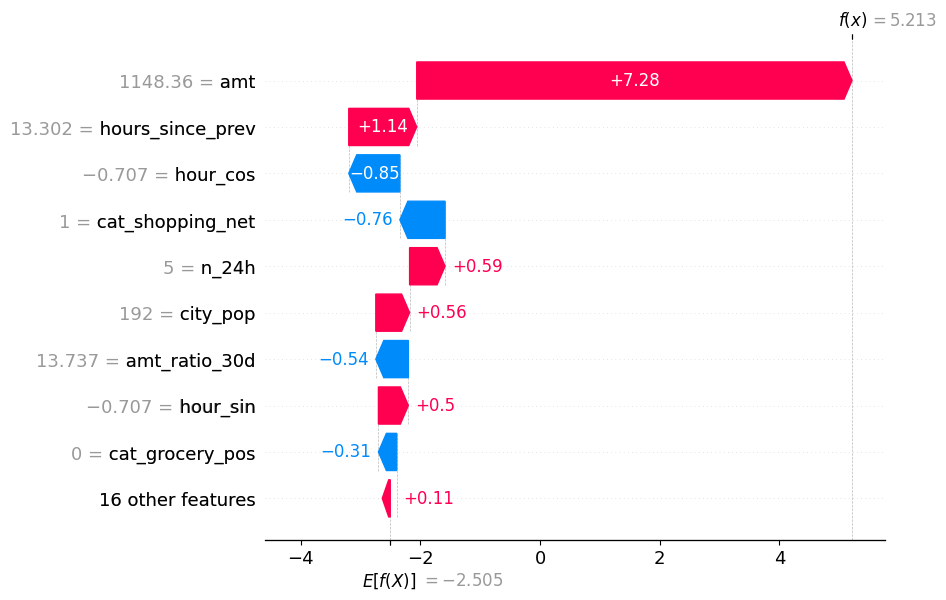

===== Random Forest


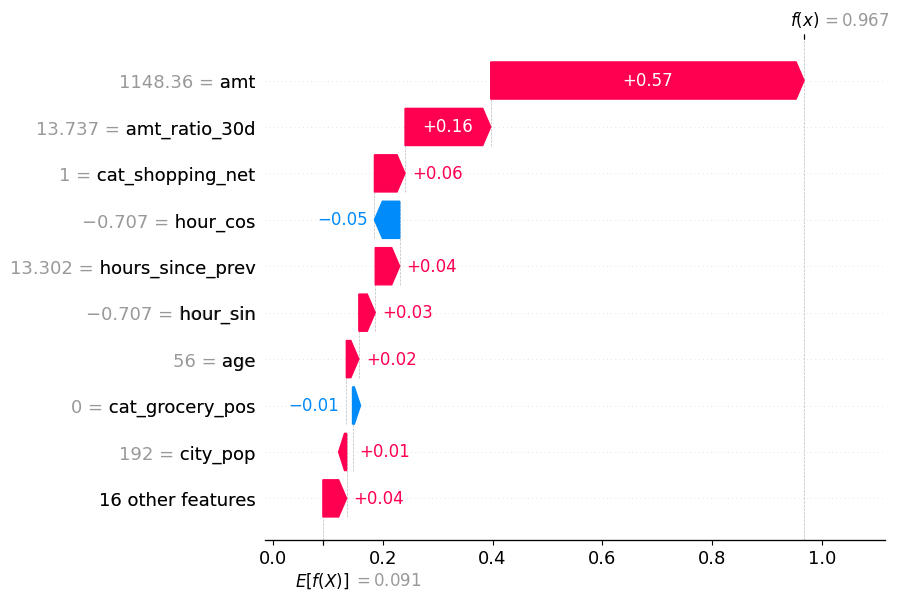

===== Régression logistique pondérée


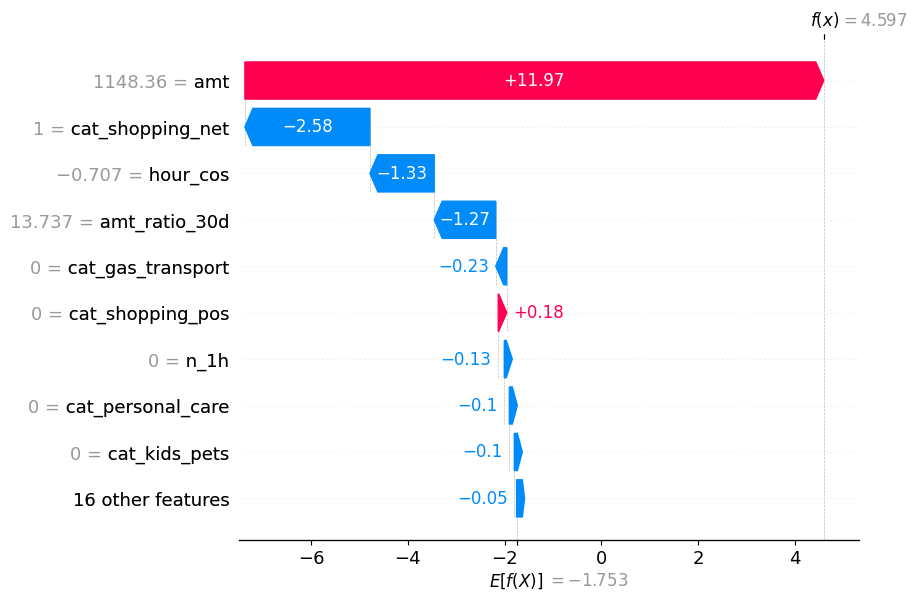

===== Isolation Forest


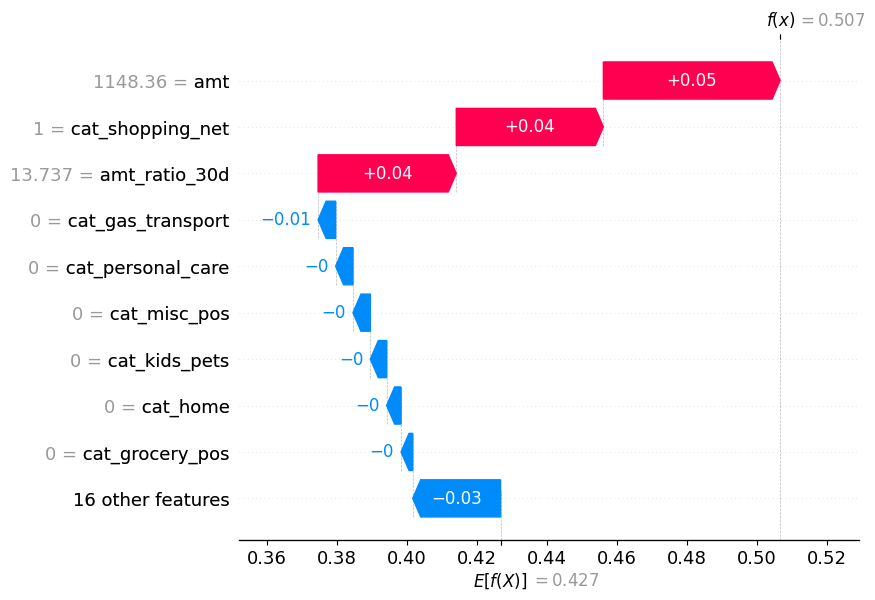

===== LOF


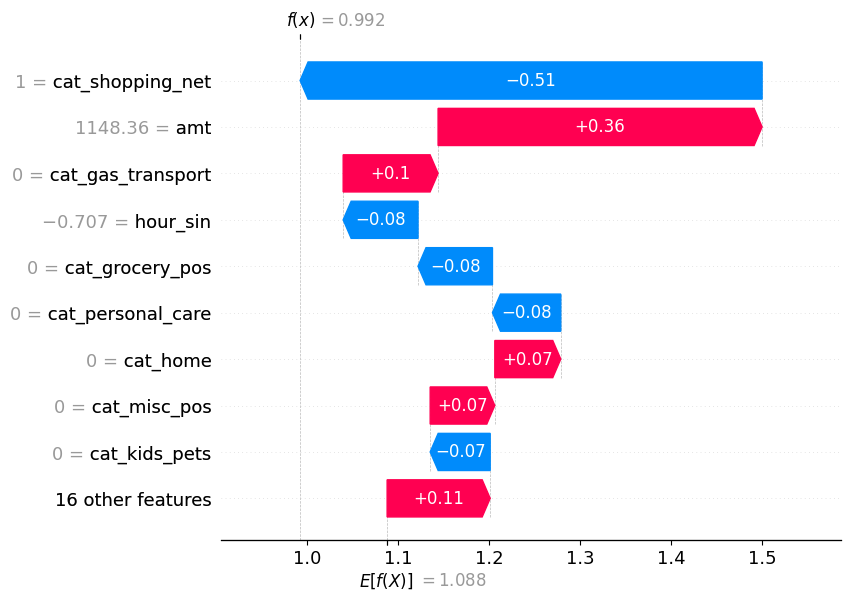

===== Autoencodeur


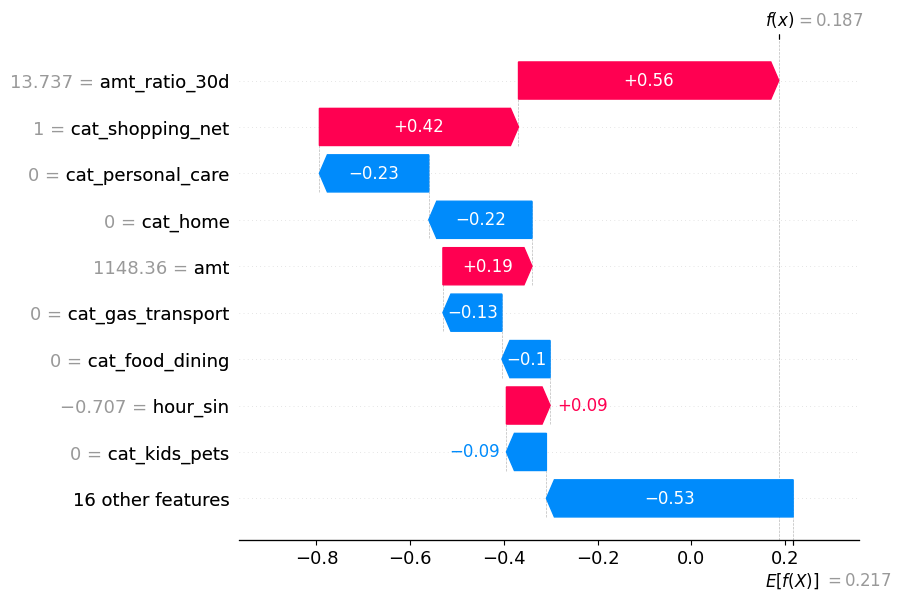

In [150]:
for nom, e in expls.items():
    print("=====", nom)
    shap.plots.waterfall(e[i_alerte], max_display=10)

In [151]:
LIBELLES = {
    "amt": "Montant de la transaction",
    "hour_sin": "Heure de la transaction", "hour_cos": "Heure de la transaction",
    "dow": "Jour de la semaine", "age": "Âge du client",
    "city_pop": "Population de la ville", "distance_km": "Distance client-marchand",
    "n_1h": "Nombre de transactions dans la dernière heure",
    "n_24h": "Nombre de transactions sur 24 h",
    "amt_ratio_30d": "Montant inhabituel pour cette carte (30 j)",
    "hours_since_prev": "Délai depuis la transaction précédente",
}

def libelle(v):
    return "Catégorie : " + v[4:] if v.startswith("cat_") else LIBELLES.get(v, v)

def codes_motifs(e, i, n=4):
    t = pd.Series(e.values[i], index=cols)
    t = t[t > 0].sort_values(ascending=False)
    return list(dict.fromkeys(libelle(v) for v in t.index))[:n]

lignes = [[nom, " | ".join(codes_motifs(e, i_alerte))] for nom, e in expls.items()]
display(pd.DataFrame(lignes, columns=["Modèle", "Codes motifs (transaction choisie)"]))

,Modèle,Codes motifs (transaction choisie)
0,LightGBM,Montant de la transaction | Délai depuis la tr...
1,XGBoost (sous-éch. 10:1),Montant de la transaction | Délai depuis la tr...
2,Random Forest,Montant de la transaction | Montant inhabituel...
3,Régression logistique pondérée,Montant de la transaction | Catégorie : shoppi...
4,Isolation Forest,Montant de la transaction | Catégorie : shoppi...
5,LOF,Montant de la transaction | Catégorie : gas_tr...
6,Autoencodeur,Montant inhabituel pour cette carte (30 j) | C...
